# Automated Galaxy Morphology Classification

**COMP9444 Neural Networks and Deep Learning - Group Project**

This notebook presents an end-to-end study of galaxy morphology classification
using the Galaxy10 DECaLS dataset. It covers the project motivation, data source,
exploratory data analysis, preprocessing, model training, model comparison,
error analysis, and Grad-CAM interpretability.

> **Colab setup:** Before running the notebook, upload
> `COMP9444-Galaxy-Morphology-Classification.zip` to `/content/`.


In [11]:
from pathlib import Path
import os

ZIP_PATH = Path("/content/COMP9444-Galaxy-Morphology-Classification.zip")
PROJECT_ROOT = Path("/content/COMP9444-Galaxy-Morphology-Classification")

if not PROJECT_ROOT.exists():
    !unzip -q "$ZIP_PATH" -d /content

print("Project root:", PROJECT_ROOT)
print("Exists:", PROJECT_ROOT.exists())

Project root: /content/COMP9444-Galaxy-Morphology-Classification
Exists: True


In [12]:
%cd /content/COMP9444-Galaxy-Morphology-Classification

/content/COMP9444-Galaxy-Morphology-Classification


In [13]:
!pwd
!ls

/content/COMP9444-Galaxy-Morphology-Classification
data  notebooks  outputs  README.md  reports  requirements.txt	src


In [14]:
!pip install -q -r requirements.txt

# 1. Introduction and Motivation

Large astronomical surveys produce more galaxy images than can be classified
manually at scale. Galaxy morphology captures visible structural properties such
as smoothness, spiral arms, bars, edge-on orientation, and signs of interaction.
Automating this classification can support efficient analysis of large sky
surveys while providing a reproducible alternative to purely manual inspection.

The goal of this project is to classify each galaxy image into one of ten
morphology categories and to compare neural-network architectures and
pretraining strategies under a shared experimental protocol.


# 2. Data Source

The project uses **Galaxy10 DECaLS**, accessed through
`astroNN.datasets.load_galaxy10`. The dataset contains **17,736 RGB galaxy
images**, each with a resolution of **256 × 256 pixels**, and one integer label
from **10 morphology classes**.

The ten classes describe disturbed and merging systems, smooth galaxies of
different shapes, barred and unbarred spirals, and edge-on galaxies with or
without a central bulge.


# 3. Exploratory Data Analysis

The following analysis verifies the dataset dimensions and split sizes, examines
class balance, visualizes representative images, and measures basic pixel
statistics. These checks establish the main data challenges before model
training.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.evaluation.metrics import CLASS_NAMES
from src.preprocessing.dataloader import build_dataloaders


eda_train_loader, eda_val_loader, eda_test_loader = build_dataloaders(
    batch_size=32,
    train_ratio=0.8,
    val_ratio=0.1,
    test_ratio=0.1,
    random_state=42,
    num_workers=0,
)

eda_loaders = {
    "Train": eda_train_loader,
    "Validation": eda_val_loader,
    "Test": eda_test_loader,
}


## 3.1 Dataset properties and split sizes


In [ ]:
split_sizes = {
    split_name: len(loader.dataset)
    for split_name, loader in eda_loaders.items()
}

total_samples = sum(split_sizes.values())
raw_train_images = eda_train_loader.dataset.images

print(f"Total samples: {total_samples:,}")
print(f"Number of classes: {len(CLASS_NAMES)}")
print(f"Raw image shape: {raw_train_images.shape[1:]}")
print(f"Raw image dtype: {raw_train_images.dtype}")
print()

for split_name, split_size in split_sizes.items():
    percentage = 100 * split_size / total_samples
    print(f"{split_name:>10}: {split_size:>5,} ({percentage:5.2f}%)")


The stratified split uses 80% of the images for training and 10% each
for validation and testing. A fixed random seed of 42 makes the split
reproducible across all model experiments.


## 3.2 Class distribution


In [ ]:
distribution_records = []

for split_name, loader in eda_loaders.items():
    split_labels = np.asarray(loader.dataset.labels, dtype=np.int64)
    counts = np.bincount(split_labels, minlength=len(CLASS_NAMES))

    for class_index, (class_name, count) in enumerate(
        zip(CLASS_NAMES, counts)
    ):
        distribution_records.append(
            {
                "Split": split_name,
                "Class index": class_index,
                "Class": class_name,
                "Count": int(count),
                "Percentage": 100 * count / len(split_labels),
            }
        )

class_distribution_df = pd.DataFrame(distribution_records)

display(
    class_distribution_df.pivot(
        index=["Class index", "Class"],
        columns="Split",
        values="Count",
    ).reset_index()
)


In [ ]:
distribution_plot_df = class_distribution_df.pivot(
    index="Class",
    columns="Split",
    values="Count",
).loc[CLASS_NAMES, ["Train", "Validation", "Test"]]

axis = distribution_plot_df.plot(
    kind="bar",
    figsize=(13, 5.5),
    color=["#6EA8D7", "#86BFA5", "#E6A57E"],
    edgecolor="none",
)

axis.set_title("Galaxy10 DECaLS class distribution by split")
axis.set_xlabel("Morphology class")
axis.set_ylabel("Number of images")
axis.tick_params(axis="x", rotation=35)
axis.legend(title=None)
axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


The distribution is not uniform across morphology classes. The
stratified splitting procedure preserves approximately the same class
proportions in the training, validation, and test sets. Because minority classes
would be underrepresented by overall accuracy alone, **Macro-F1** is used as a
primary evaluation metric later in the notebook.


## 3.3 Representative images


In [ ]:
train_dataset_for_display = eda_train_loader.dataset
train_labels_for_display = np.asarray(
    train_dataset_for_display.labels,
    dtype=np.int64,
)

figure, axes = plt.subplots(2, 5, figsize=(15, 6.5))

for class_index, axis in enumerate(axes.flat):
    sample_index = int(
        np.flatnonzero(train_labels_for_display == class_index)[0]
    )
    image, label = train_dataset_for_display[sample_index]

    axis.imshow(image.permute(1, 2, 0).numpy())
    axis.set_title(f"{class_index}: {CLASS_NAMES[int(label)]}", fontsize=10)
    axis.axis("off")

figure.suptitle(
    "One representative training image from each morphology class",
    fontsize=14,
)
plt.tight_layout()
plt.show()


The examples show meaningful visual differences between broad
categories, but several boundaries are fine-grained. In particular, smooth
subclasses differ mainly in elongation, spiral subclasses differ in arm
tightness or the presence of a bar, and disturbed galaxies can resemble loose
spirals. Variation in orientation, scale, brightness, and background noise adds
further difficulty.


## 3.4 Pixel statistics and batch verification


In [ ]:
statistics_sample_size = min(256, len(raw_train_images))
statistics_indices = np.linspace(
    0,
    len(raw_train_images) - 1,
    statistics_sample_size,
    dtype=int,
)
statistics_sample = (
    raw_train_images[statistics_indices].astype(np.float32) / 255.0
)

channel_mean = statistics_sample.mean(axis=(0, 1, 2))
channel_std = statistics_sample.std(axis=(0, 1, 2))

pixel_statistics_df = pd.DataFrame(
    {
        "Channel": ["Red", "Green", "Blue"],
        "Mean": channel_mean,
        "Standard deviation": channel_std,
    }
)

display(pixel_statistics_df.round(4))

sample_batch_images, sample_batch_labels = next(iter(eda_train_loader))
print(f"Batch image shape: {tuple(sample_batch_images.shape)}")
print(f"Batch label shape: {tuple(sample_batch_labels.shape)}")
print(
    "Tensor value range:",
    f"[{sample_batch_images.min().item():.3f}, "
    f"{sample_batch_images.max().item():.3f}]",
)


# 4. Preprocessing and Data Challenges

The shared data pipeline performs the following operations:

1. Load Galaxy10 DECaLS through `astroNN`.
2. Convert labels to `int64` for compatibility with cross-entropy loss.
3. Create a reproducible stratified 80/10/10 split.
4. Convert images from NumPy arrays to PyTorch tensors.
5. Resize model inputs to 224 × 224 pixels.
6. Apply ImageNet normalization to all model inputs.
7. Apply random horizontal flipping only to the training set.

Validation and test images use deterministic transforms so that evaluation is
stable and comparable. The main challenges are class imbalance, subtle
inter-class differences, variable orientation and scale, and noisy or ambiguous
galaxy structures.


In [ ]:
from src.baseline.train_baseline import build_transforms

training_transform, evaluation_transform = build_transforms()

print("Training transform:")
print(training_transform)
print()
print("Validation/test transform:")
print(evaluation_transform)


The exploratory analysis and preprocessing choices establish a
consistent input pipeline for every model. The following sections train the
baseline and main architectures under this shared protocol, then compare their
performance.


# **Model Training**



## 1. Training Pipeline Overview
This section trains all classification models used in our experiments.

The training pipeline is designed with a shared training protocol to ensure a fair comparison between different network architectures and different pretraining strategies.

Overall workflow:

1. Load the Galaxy10 dataset.
2. Apply preprocessing and data augmentation.
3. Construct train/validation/test dataloaders.
4. Train each model using the same optimization protocol.
5. Save checkpoints, prediction files and evaluation summaries.
6. Pass the generated outputs to the Model Evaluation section.

## 2. Data Preparation

All models use the same preprocessing pipeline implemented under `src/preprocessing`.

Files:

- `dataset.py`
  - Defines the custom PyTorch Dataset for Galaxy10 images.

- `split.py`
  - Splits the dataset into train / validation / test sets using a stratified 80/10/10 split with `random_state=42`.

- `transforms.py`
  - Defines basic image transforms.

- `dataloader.py`
  - Builds the DataLoader objects used by all models.

Using the same preprocessing pipeline guarantees that every model is trained and evaluated on exactly the same data split.

## 3. Shared Training Framework（core part of training procedure)

The shared training protocol is implemented in:

`src/baseline/train_baseline.py`

Besides defining the baseline models, this file also provides the common `train_one()` function used by every model.

The shared training framework performs:

- model initialization
- optimizer construction (AdamW)
- training loop
- validation after each epoch
- best checkpoint selection based on validation Macro-F1
- test evaluation
- saving checkpoints
- saving JSON result files
- saving prediction files

Keeping the same training protocol ensures that performance differences mainly come from the model architecture or the pretraining strategy instead of different training settings.

## 4. Baseline Models

The baseline models are implemented in:

`src/baseline/train_baseline.py`

Two baseline models are included:

- SimpleCNN
  - A lightweight CNN trained from scratch.
  - Provides the lower performance bound.

- VGG16
  - ImageNet pretrained.
  - Serves as the transfer learning baseline.

## 5. Main Models

The following architectures are evaluated.

| Model | File | Pretraining |
|------|------|-------------|
| DenseNet121 | `src/models/densenet121.py` | ImageNet |
| ResNet50 | `src/models/resnet50_imagenet.py` | ImageNet |
| ResNet50 | `src/models/resnet50.py` | ZooBot |
| ConvNeXT-Nano | `src/models/convnext_nano_imagenet.py` | ImageNet |
| ConvNeXT-Nano | `src/models/convnext_nano.py` | ZooBot |

Each model file only defines the network architecture.

The actual training procedure is reused from the shared `train_one()` function.

## 6. Experimental Design

Two complementary experiments are conducted.

### Experiment 1: Cross-Architecture Comparison

The first experiment compares representative CNN architectures under the same ImageNet pretraining protocol. By keeping the pretraining source identical, the comparison focuses on the influence of network architecture.

The evaluated models include:

- **SimpleCNN** – a lightweight convolutional neural network trained from scratch, providing a lower-bound baseline.
- **VGG16** – a classical deep CNN using stacked 3×3 convolutions, widely adopted as a transfer learning baseline.
- **DenseNet121** – introduces dense connectivity between layers, encouraging feature reuse and improving parameter efficiency.
- **ResNet50 (ImageNet)** – employs residual skip connections to enable effective training of deeper networks.
- **ConvNeXT-Nano (ImageNet)** – a modern CNN architecture inspired by Transformer design principles while retaining convolutional operations.

Since all pretrained models use ImageNet weights and share the same training protocol, performance differences mainly reflect architectural characteristics.

### Experiment 2: Pretraining Ablation

The second experiment investigates the effect of different pretraining domains while keeping the network architecture unchanged.

Two pretraining strategies are compared:

- **ImageNet Pretraining**
  - Models are initialized using weights learned from the ImageNet dataset, a large-scale natural image benchmark containing over one million everyday object images.
  - This represents the standard transfer learning approach widely used in computer vision.

- **ZooBot Pretraining**
  - Models are initialized using weights released by ZooBot, which were pretrained on Galaxy Zoo galaxy morphology data.
  - Since the source domain is astronomical imagery rather than natural images, ZooBot is expected to learn more domain-specific visual features.

> **Note:** The pretraining ablation is limited to **ResNet50** and **ConvNeXT-Nano** because ZooBot only provides publicly available pretrained weights for these two architectures. Equivalent ZooBot-pretrained versions of VGG16 and DenseNet121 are not available, so extending the comparison to those models would not be possible while maintaining a fair experimental setting.

By comparing ImageNet and ZooBot initialization on the same architecture (ResNet50 and ConvNeXT-Nano), the experiment isolates the contribution of domain-specific pretraining.

Therefore, the performance difference reflects the contribution of domain-specific pretraining.

### Therefore,

- Experiment 1 isolates the effect of network architecture.

- Experiment 2 isolates the effect of the pretraining domain.

Together, these two experiments provide a comprehensive evaluation of both architectural design and transfer learning strategy.

| Experiment | Controlled Variable | Changed Variable | Models | Purpose |
|------------|---------------------|------------------|--------|---------|
| Cross-Architecture Comparison | ImageNet pretraining | Network architecture | SimpleCNN, VGG16, DenseNet121, ResNet50, ConvNeXT-Nano | Compare different CNN architectures under the same pretraining setting |
| Pretraining Ablation | Network architecture | Pretraining source (ImageNet vs ZooBot) | ResNet50, ConvNeXT-Nano | Evaluate the impact of domain-specific pretraining |

## 7. Run Training

Train Baseline Models：

In [15]:
!python -m src.baseline.train_baseline

2026-07-28 23:08:35.927971: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-28 23:08:35.961255: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Galaxy10_DECals.h5: 100% 2.73G/2.74G [00:28<00:00, 95.8MB/s]Downloaded Galaxy10 successfully to /root/.astroNN/datasets/Galaxy10_DECals.h5
Galaxy10_DECals.h5: 2.74GB [00:30, 89.8MB/s]                
[simplecnn] epoch=01 train_loss=2.0878 val_acc=0.3202 val_macro_f1=0.2219
[simplecnn] epoch=02 train_loss=1.9417 val_acc=0.3546 val_macro_f1=0.2336
[simp

DenseNet：

In [16]:
!python -m src.models.densenet121

2026-07-28 23:18:06.053789: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-28 23:18:06.086559: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100% 30.8M/30.8M [00:00<00:00, 88.1MB/s]
/root/.astroNN/datasets/Galaxy10_DECals.h5 was found!
[densenet121] epoch=01 train_loss=0.9136 val_acc=0.8067 val_macro_f1=0.7750
[densenet121] epoch=02 train_loss=0.5141 va

ResNet50 (ZooBot)

In [17]:
!python -m src.models.resnet50

2026-07-28 23:22:51.041117: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-28 23:22:51.073743: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
config.json: 100% 753/753 [00:00<00:00, 6.19MB/s]

pytorch_model.bin: downloading bytes:  82% 77.8M/94.3M [00:02<00:00, 70.7MB/s, 6.34MB/s  ]
pytorch_model.bin: downloading bytes: 100% 88.6M/88.6M [00:02<00:00, 32.1MB/s, 7.96MB/s  ]
pytorch_model.bin: reconstructing file: 100% 94.3M/94.3M [00:02<00:00, 34.1MB/s, 8.83MB/s  ]
/root/.astroNN/datasets/Gal

ResNet50 (ImageNet)

In [18]:
!python -m src.models.resnet50_imagenet

2026-07-28 23:26:52.633943: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-28 23:26:52.666071: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.

model.safetensors: downloading bytes:   1% 1.22M/102M [00:00<00:40, 2.50MB/s, 4.58kB/s  ]
model.safetensors: downloading bytes:   3% 3.51M/102M [00:00<00:13, 7.18MB/s,  120kB/s  ]
model.safetensors: downloading bytes:  11% 10.9M/102M [00:00<00:04, 18.9MB/s,  458kB/s  ]
model.safetensors: downloading bytes:  40% 41.0M/102M [00:01<00:02, 29.3MB/s, 3.73

ConvNeXT-Nano (ZooBot)

In [19]:
!python -m src.models.convnext_nano

2026-07-28 23:30:52.648956: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-28 23:30:52.681515: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
config.json: 100% 659/659 [00:00<00:00, 5.61MB/s]

pytorch_model.bin: downloading bytes:  87% 52.2M/59.9M [00:02<00:00, 52.0MB/s, 4.32MB/s  ]
pytorch_model.bin: downloading bytes: 100% 56.9M/56.9M [00:02<00:00, 26.3MB/s, 5.20MB/s  ]
pytorch_model.bin: reconstructing file: 100% 59.9M/59.9M [00:02<00:00, 27.6MB/s, 5.67MB/s  ]
/root/.astroNN/datasets/Gal

ConvNeXT-Nano (ImageNet)

In [20]:
!python -m src.models.convnext_nano_imagenet

2026-07-28 23:35:39.007990: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-28 23:35:39.040290: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.

model.safetensors: downloading bytes:  92% 57.3M/62.4M [00:01<00:00, 60.6MB/s, 4.77MB/s  ]
model.safetensors: downloading bytes: 100% 59.5M/59.5M [00:01<00:00, 39.9MB/s, 5.58MB/s  ]
model.safetensors: reconstructing file: 100% 62.4M/62.4M [00:01<00:00, 41.9MB/s, 6.01MB/s  ]
/root/.astroNN/datasets/Galaxy10_DECals.h5 was found!
[convnext_nano_imagenet

In [21]:
!ls outputs/results

baseline_reference.md			resnet50_imagenet_predictions.npz
convnext_nano_imagenet.json		resnet50_zoobot.json
convnext_nano_imagenet_predictions.npz	resnet50_zoobot_predictions.npz
convnext_nano_zoobot.json		simplecnn.json
convnext_nano_zoobot_predictions.npz	simplecnn_predictions.npz
densenet121.json			vgg16.json
densenet121_predictions.npz		vgg16_predictions.npz
resnet50_imagenet.json


# **Model Evaluation**

This section evaluates all trained models using a unified evaluation framework.

The evaluation pipeline consists of four reusable modules implemented under `src/evaluation`:

- `metrics.py` – computes prediction metrics shared by all models.
- `compare_models.py` – compares model performance and generates summary tables and plots.
- `confusion_matrix.py` – visualizes prediction confusion between galaxy morphology classes.
- `gradcam.py` – provides Grad-CAM visual explanations for model predictions.

The outputs generated during model training (checkpoints, prediction files and JSON summaries) are used as inputs for all evaluation analyses.

## 1. Load Evaluation Results

This section initializes the evaluation environment.

It loads the project directories and imports the evaluation utilities implemented under `src/evaluation`.

The notebook reads all JSON result files generated during model training from:

```
outputs/results/
```

These files contain:

- overall evaluation metrics
- per-class metrics
- confusion matrices
- training statistics
- inference statistics

The loaded results serve as the input for all subsequent analyses.

In [22]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

RESULT_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Result directory:", RESULT_DIR)
print("Figure directory:", FIGURE_DIR)

Project root: /content/COMP9444-Galaxy-Morphology-Classification
Result directory: /content/COMP9444-Galaxy-Morphology-Classification/outputs/results
Figure directory: /content/COMP9444-Galaxy-Morphology-Classification/outputs/figures


## 2. Overall Model Comparison

This section performs a quantitative comparison across all trained models.

The comparison is implemented in:

`src/evaluation/compare_models.py`

The script automatically loads the evaluation summaries produced during training and constructs:

- overall performance table
- model ranking
- per-class performance table
- pretraining ablation table

The primary evaluation metric is Macro-F1 because the Galaxy10 dataset is class-imbalanced.

Accuracy is also reported for completeness.

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from src.evaluation.compare_models import (
    build_per_class_dataframe,
    build_pretraining_ablation_dataframe,
    build_summary_dataframe,
    get_best_model,
    load_model_results,
)

from src.evaluation.confusion_matrix import (
    plot_confusion_matrix,
)

from src.evaluation.metrics import (
    CLASS_NAMES,
)

In [24]:
import matplotlib as mpl
import matplotlib.pyplot as plt

PALETTE = {
    "navy": "#4E6E81",
    "blue": "#6F8FA6",
    "sage": "#8FA89A",
    "sand": "#C2AA83",
    "rose": "#B58A8A",
    "lavender": "#9A94AC",
    "slate": "#707A83",
    "light_grey": "#D9DDE1",
    "grid": "#E7E9EC",
    "text": "#30343B",
    "muted_text": "#626972",
    "background": "#FAFAFA",
}

METRIC_COLOURS = [
    "#6EA8D7",
    "#E6A57E",
    "#86BFA5",
]

COMPLEXITY_COLOURS = {
    "ResNet50 Zoobot": "#65A9E0",
    "ConvNeXT-Nano Zoobot": "#67C3A3",
    "ConvNeXT-Nano ImageNet": "#92B7E8",
    "VGG16": "#F0AE72",
    "DenseNet121": "#B79BE2",
    "ResNet50 ImageNet": "#E99B9B",
    "SimpleCNN": "#AEB9C4",
}

MODEL_COLOURS = {
    "ResNet50 Zoobot": "#6EA8D7",
    "ConvNeXT-Nano Zoobot": "#86BFA5",
    "ConvNeXT-Nano ImageNet": "#9CB9E2",
    "VGG16": "#E6A57E",
    "DenseNet121": "#B7A6D9",
    "ResNet50 ImageNet": "#E59A9A",
    "SimpleCNN": "#B7C0C8",
}

IMAGENET_COLOURS = [
    "#6EA8D7",
    "#86BFA5",
    "#E6A57E",
    "#B7A6D9",
]

PAIR_COLOURS = [
    "#76A9DA",
    "#8FC4A9",
]

LINE_COLOURS = {
    "ResNet50 Zoobot": "#4F92CC",
    "ConvNeXT-Nano Zoobot": "#6FB394",
    "ConvNeXT-Nano ImageNet": "#8EAFE0",
    "VGG16": "#E7A06F",
    "DenseNet121": "#A794CF",
    "ResNet50 ImageNet": "#DE8F8F",
    "SimpleCNN": "#AAB4BD",
}

HEATMAP_CMAP = "YlGnBu"

mpl.rcParams.update(
    {
        # Font
        "font.family": "DejaVu Sans",
        "font.size": 10,

        # Titles and labels
        "axes.titlesize": 13,
        "axes.titleweight": "normal",
        "axes.labelsize": 10,
        "axes.labelcolor": PALETTE["text"],

        # Tick labels
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "xtick.color": PALETTE["muted_text"],
        "ytick.color": PALETTE["muted_text"],

        # Figure appearance
        "figure.facecolor": "white",
        "axes.facecolor": "white",

        # Borders
        "axes.edgecolor": "#C9CDD2",
        "axes.linewidth": 0.7,
        "axes.spines.top": False,
        "axes.spines.right": False,

        # Grid
        "axes.grid": False,
        "grid.color": PALETTE["grid"],
        "grid.linewidth": 0.7,
        "grid.alpha": 0.75,

        # Legend
        "legend.frameon": False,
        "legend.fontsize": 9,

        # Output quality
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "savefig.facecolor": "white",
        "savefig.bbox": "tight",
    }
)

In [25]:
results = load_model_results(RESULT_DIR)

print(f"Loaded {len(results)} model result files:")

for model_name in results:
    print("-", model_name)

Loaded 7 model result files:
- convnext_nano_imagenet
- convnext_nano_zoobot
- densenet121
- resnet50_imagenet
- resnet50_zoobot
- simplecnn
- vgg16


In [26]:
summary_df = build_summary_dataframe(results)

summary_df.round(
    {
        "Accuracy": 4,
        "Macro-F1": 4,
        "Weighted-F1": 4,
        "Parameters (M)": 2,
        "Training Time (min)": 2,
        "Inference Time (s)": 3,
    }
)

,Model Key,Model,Pretraining,Accuracy,Macro-F1,Weighted-F1,Parameters,Parameters (M),Best Epoch,Training Time (min),Inference Time (s),Test Samples,Inference per Image (ms),Throughput (images/s)
0,convnext_nano_zoobot,ConvNeXT-Nano Zoobot,Zoobot,0.8828,0.8602,0.8794,14958970,14.96,3,4.14,0.789,1774,0.444749,2248.460075
1,resnet50_zoobot,ResNet50 Zoobot,Zoobot,0.8720,0.8525,0.8667,23528522,23.53,13,3.38,0.789,1774,0.444484,2249.797405
2,densenet121,DenseNet121,ImageNet,0.8354,0.8229,0.8336,6964106,6.96,6,4.13,0.796,1774,0.448889,2227.722394
3,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,ImageNet,0.8405,0.8218,0.8406,14958970,14.96,2,4.14,0.784,1774,0.441781,2263.566695
4,vgg16,VGG16,ImageNet,0.8236,0.7998,0.8198,134301514,134.30,10,5.83,1.121,1774,0.631717,1582.986854
5,resnet50_imagenet,ResNet50 ImageNet,ImageNet,0.8005,0.7801,0.7970,23528522,23.53,12,3.38,0.789,1774,0.444784,2248.283372
6,simplecnn,SimpleCNN,None,0.4639,0.3846,0.4344,391946,0.39,15,1.77,0.742,1774,0.418349,2390.351185



The table above summarizes the overall performance of all seven trained models together with their computational characteristics, including model size, training time, inference speed, and evaluation metrics.

**Macro-F1 is used as the primary evaluation metric because the Galaxy10 dataset is class-imbalanced.** Accuracy and Weighted-F1 are also reported to provide complementary information about overall classification performance.

Several observations can be made:

- **ConvNeXt-Nano with ZooBot pretraining achieves the best overall performance**, obtaining the highest Accuracy (88.28%), Macro-F1 (86.02%), and Weighted-F1 (87.94%).

- **All pretrained models substantially outperform the SimpleCNN baseline**, demonstrating that transfer learning is essential for astronomical image classification on relatively small datasets.

- **DenseNet121 achieves the strongest performance among the ImageNet-pretrained models**, indicating that dense feature reuse is highly effective for Galaxy10.

- **ConvNeXt-Nano outperforms ResNet50 under both ImageNet and ZooBot pretraining**, suggesting that the ConvNeXt architecture provides stronger feature extraction capability for galaxy morphology classification.

- **Model size alone does not determine performance.** For example, VGG16 contains the largest number of parameters (134M) but performs worse than DenseNet121 and ConvNeXt-Nano, indicating that modern network architectures are more parameter-efficient.

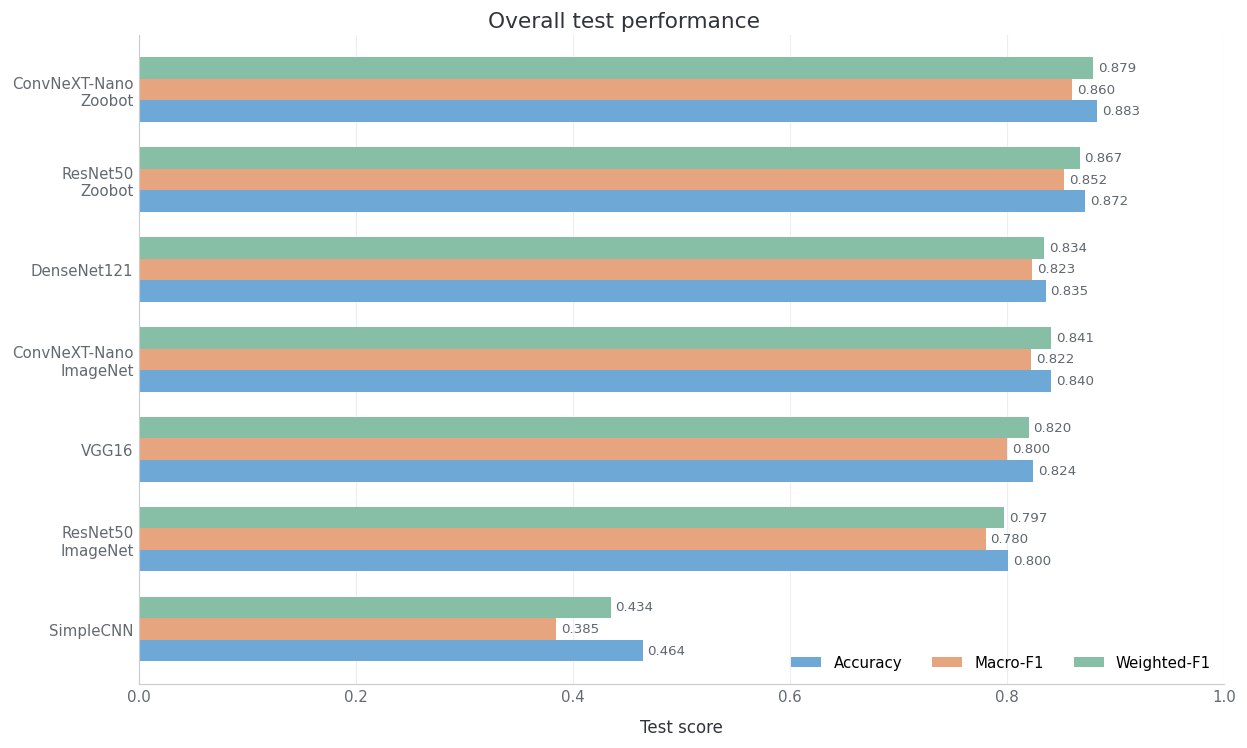

In [27]:
performance_df = (
    summary_df
    .sort_values("Macro-F1", ascending=True)
    .reset_index(drop=True)
    .copy()
)

display_names = {
    "ResNet50 Zoobot": "ResNet50\nZoobot",
    "ConvNeXT-Nano Zoobot": "ConvNeXT-Nano\nZoobot",
    "ConvNeXT-Nano ImageNet": "ConvNeXT-Nano\nImageNet",
    "ResNet50 ImageNet": "ResNet50\nImageNet",
    "DenseNet121": "DenseNet121",
    "VGG16": "VGG16",
    "SimpleCNN": "SimpleCNN",
}

performance_df["Display Model"] = (
    performance_df["Model"].map(display_names)
)

metrics_to_plot = [
    "Accuracy",
    "Macro-F1",
    "Weighted-F1",
]

axis = (
    performance_df
    .set_index("Display Model")[metrics_to_plot]
    .plot(
        kind="barh",
        figsize=(10.5, 6.8),
        width=0.72,
        color=METRIC_COLOURS,
        edgecolor="none",
    )
)

figure = axis.get_figure()
axis.set_title("")
figure.suptitle(
    "Overall test performance",
    x=0.5,
    y=0.91,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Test score",
    labelpad=8,
)
axis.set_ylabel("")
axis.set_xlim(0, 1)

axis.grid(
    axis="x",
    color="#E9EDF1",
    linewidth=0.7,
    alpha=0.9,
)

axis.set_axisbelow(True)

axis.legend(
    title=None,
    loc="lower right",
    ncol=3,
    frameon=False,
)

for container in axis.containers:
    labels = [
        f"{bar.get_width():.3f}"
        for bar in container
    ]

    axis.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=8,
        color="#5E6670",
    )

axis.tick_params(
    axis="both",
    length=0,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "overall_model_performance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

**Overall Model Performance**

The figure visualizes the Accuracy, Macro-F1 and Weighted-F1 of all trained models.

**The ranking of the models is consistent across all three evaluation metrics**, indicating stable model behaviour and reliable performance comparison.

The results clearly show that:

- **ConvNeXt-Nano (ZooBot) achieves the highest performance across all metrics**, followed by ResNet50 (ZooBot).

- **ZooBot-pretrained models consistently outperform their ImageNet-pretrained counterparts**, demonstrating that domain-specific astronomical pretraining provides more transferable visual representations than generic natural-image pretraining.

- **DenseNet121 ranks first among the ImageNet-pretrained architectures**, outperforming both VGG16 and ResNet50 while using significantly fewer parameters than VGG16.

- **The SimpleCNN baseline performs substantially worse than all transfer learning models**, confirming that learning from scratch is insufficient for this dataset.

Overall, the results indicate that **both network architecture and pretraining strategy contribute significantly to classification performance**, with domain-specific pretraining providing the largest improvement.

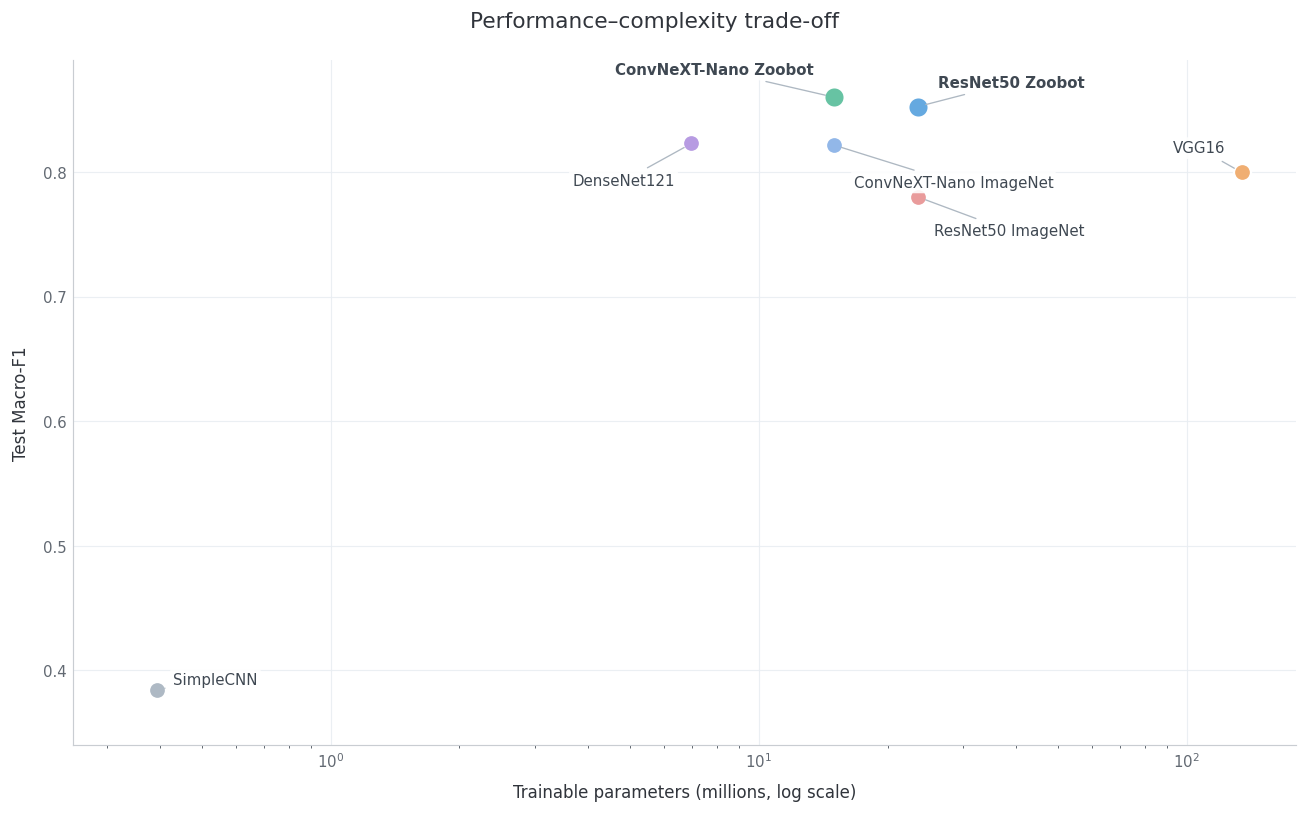

In [29]:
complexity_df = (
    summary_df
    .sort_values(
        ["Macro-F1", "Parameters (M)"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
    .copy()
)

figure, axis = plt.subplots(
    figsize=(11, 6.8),
)

annotation_settings = {
    "ResNet50 Zoobot": {
        "offset": (12, 10),
        "ha": "left",
        "va": "bottom",
    },
    "ConvNeXT-Nano Zoobot": {
        "offset": (-12, 12),
        "ha": "right",
        "va": "bottom",
    },
    "ConvNeXT-Nano ImageNet": {
        "offset": (12, -18),
        "ha": "left",
        "va": "top",
    },
    "VGG16": {
        "offset": (-10, 10),
        "ha": "right",
        "va": "bottom",
    },
    "DenseNet121": {
        "offset": (-10, -18),
        "ha": "right",
        "va": "top",
    },
    "ResNet50 ImageNet": {
        "offset": (10, -16),
        "ha": "left",
        "va": "top",
    },
    "SimpleCNN": {
        "offset": (10, 6),
        "ha": "left",
        "va": "center",
    },
}

for _, row in complexity_df.iterrows():
    model_name = row["Model"]

    is_highlight = model_name in {
        "ResNet50 Zoobot",
        "ConvNeXT-Nano Zoobot",
    }

    axis.scatter(
        row["Parameters (M)"],
        row["Macro-F1"],
        s=150 if is_highlight else 105,
        color=COMPLEXITY_COLOURS[model_name],
        edgecolor="white",
        linewidth=1.4,
        alpha=1.0,
        zorder=4,
    )

    settings = annotation_settings[model_name]

    axis.annotate(
        model_name,
        xy=(
            row["Parameters (M)"],
            row["Macro-F1"],
        ),
        xytext=settings["offset"],
        textcoords="offset points",
        ha=settings["ha"],
        va=settings["va"],
        fontsize=9,
        color="#3F4852",
        fontweight=(
            "semibold"
            if is_highlight
            else "normal"
        ),
        arrowprops={
            "arrowstyle": "-",
            "color": "#AEB8C2",
            "linewidth": 0.8,
            "shrinkA": 3,
            "shrinkB": 5,
        },
        bbox={
            "boxstyle": "round,pad=0.22",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
        },
        zorder=5,
    )

axis.set_xscale("log")

axis.set_title("")

figure.suptitle(
    "Performance–complexity trade-off",
    x=0.5,
    y=0.99,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Trainable parameters (millions, log scale)",
    labelpad=8,
)
axis.set_ylabel(
    "Test Macro-F1",
    labelpad=8,
)

axis.set_xlim(0.25, 180)
axis.set_ylim(0.34, 0.89)

axis.grid(
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.tick_params(
    axis="both",
    length=0,
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "macro_f1_vs_parameters.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

**Larger models do not necessarily achieve better classification performance.**

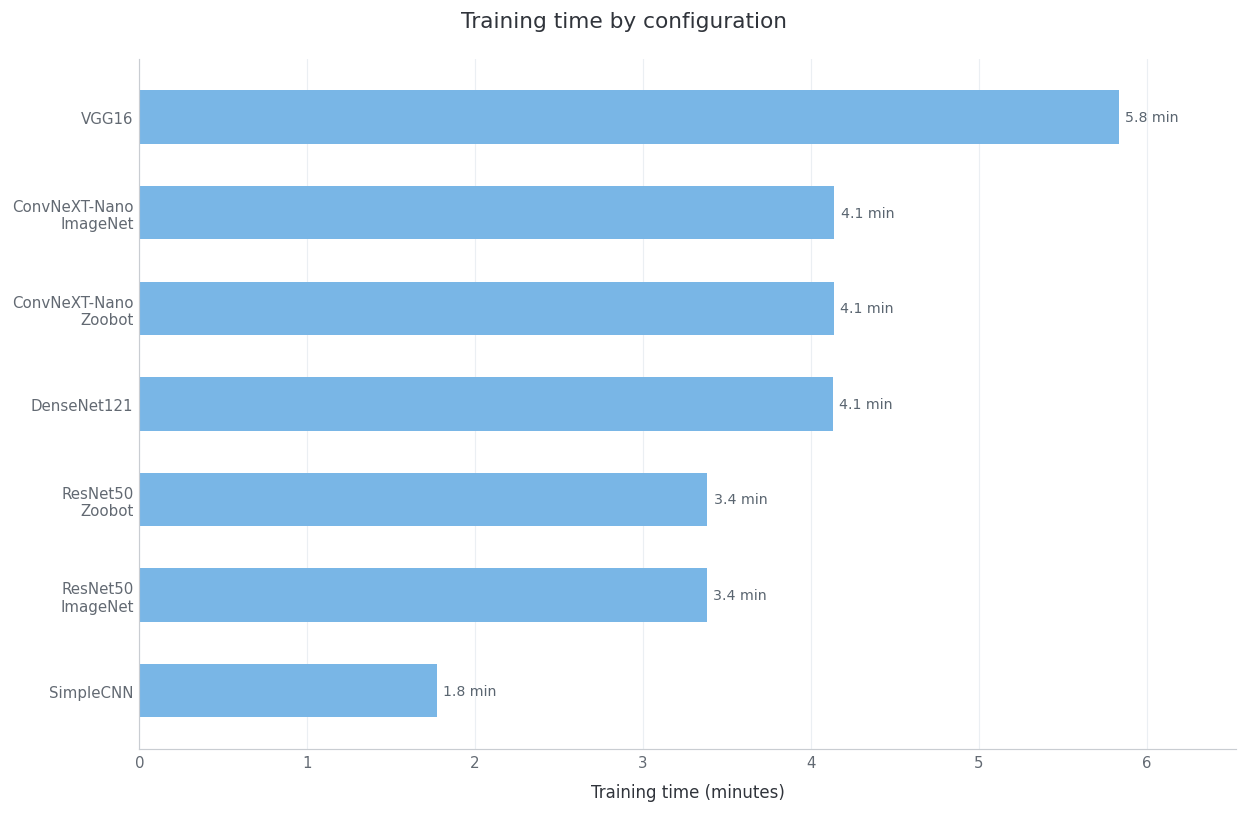

In [30]:
training_time_df = (
    summary_df
    .sort_values(
        "Training Time (min)",
        ascending=True,
    )
    .reset_index(drop=True)
    .copy()
)

training_time_df["Display Model"] = (
    training_time_df["Model"]
    .map(display_names)
)

figure, axis = plt.subplots(
    figsize=(10.5, 6.8),
)

bars = axis.barh(
    training_time_df["Display Model"],
    training_time_df["Training Time (min)"],
    color="#79B6E6",
    edgecolor="none",
    height=0.56,
)

axis.set_title("")
figure.suptitle(
    "Training time by configuration",
    x=0.5,
    y=0.99,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Training time (minutes)",
    labelpad=8,
)

axis.set_ylabel("")

axis.grid(
    axis="x",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.bar_label(
    bars,
    labels=[
        f"{value:.1f} min"
        for value in training_time_df[
            "Training Time (min)"
        ]
    ],
    padding=4,
    fontsize=8.5,
    color="#5A6570",
)

axis.tick_params(
    axis="both",
    length=0,
)

axis.margins(x=0.12)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "training_time_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

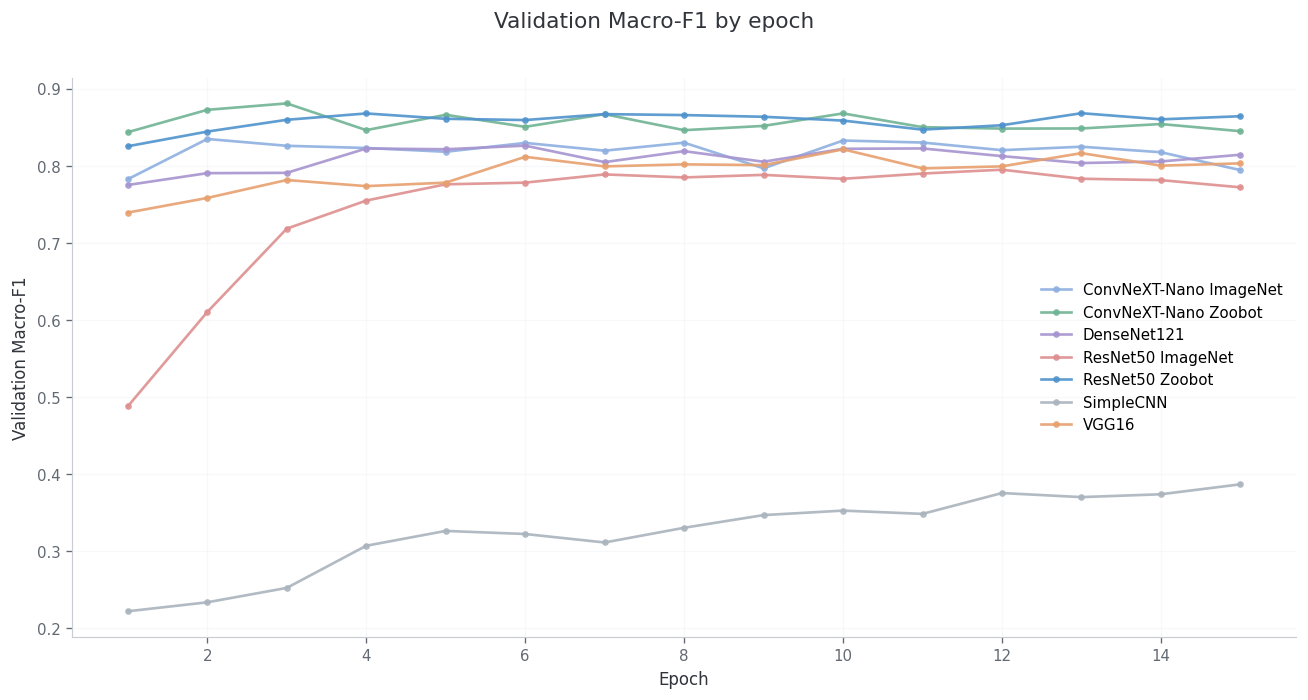

In [31]:
figure, axis = plt.subplots(figsize=(11, 6))

for model_key, result in results.items():
    history = result.get("history", {})

    epochs = history.get("epoch", [])
    val_macro_f1 = history.get("val_macro_f1", [])

    if not epochs or not val_macro_f1:
        continue

    display_name = summary_df.loc[
        summary_df["Model Key"] == model_key,
        "Model",
    ].iloc[0]

    axis.plot(
        epochs,
        val_macro_f1,
        marker="o",
        markersize=4,
        linewidth=1.6,
        color=LINE_COLOURS[display_name],
        markeredgewidth=0,
        alpha=0.9,
        label=display_name,
    )

axis.set_title("")
figure.suptitle(
    "Validation Macro-F1 by epoch",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel("Epoch")
axis.set_ylabel("Validation Macro-F1")
axis.legend()
axis.grid(alpha=0.3)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "validation_macro_f1_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

**All pretrained models converge within the first few epochs and remain stable throughout training, whereas SimpleCNN consistently underperforms.**

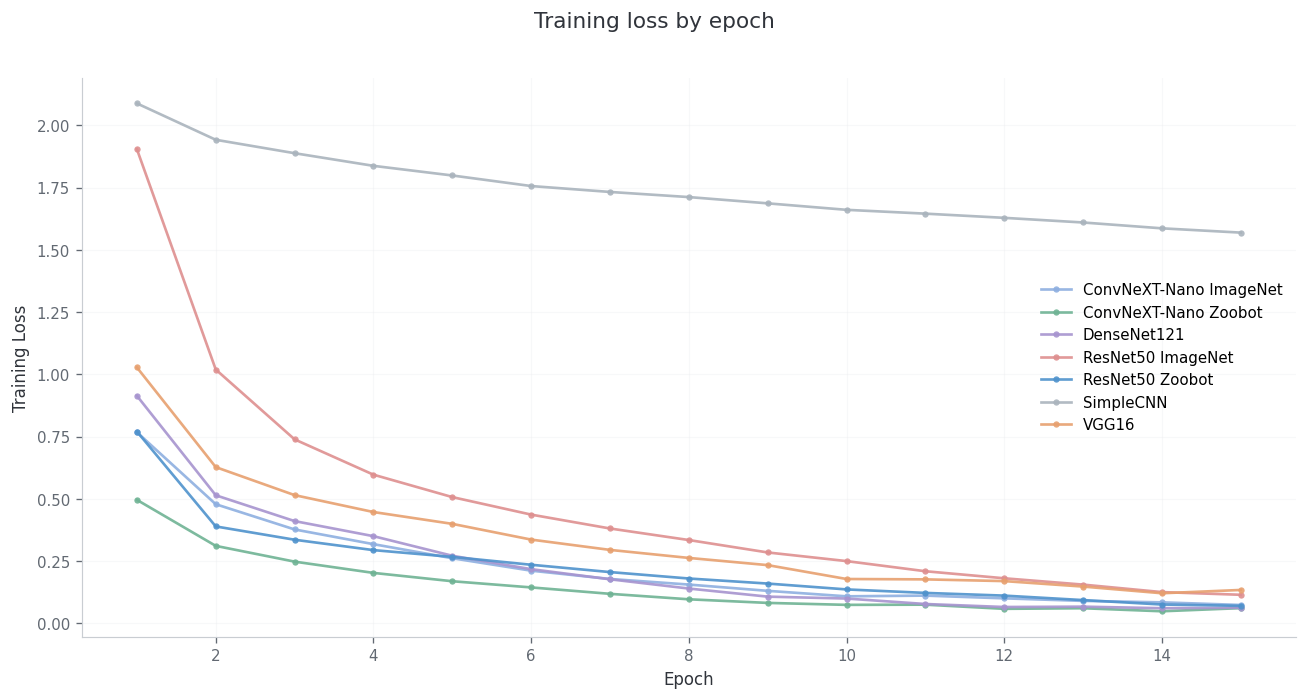

In [32]:
figure, axis = plt.subplots(figsize=(11, 6))

for model_key, result in results.items():
    history = result.get("history", {})

    epochs = history.get("epoch", [])
    train_loss = history.get("train_loss", [])

    if not epochs or not train_loss:
        continue

    display_name = summary_df.loc[
        summary_df["Model Key"] == model_key,
        "Model",
    ].iloc[0]

    axis.plot(
        epochs,
        train_loss,
        marker="o",
        markersize=3.8,
        linewidth=1.6,
        color=LINE_COLOURS[display_name],
        markeredgewidth=0,
        alpha=0.9,
        label=display_name,
    )

axis.set_title("")
figure.suptitle(
    "Training loss by epoch",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel("Epoch")
axis.set_ylabel("Training Loss")
axis.legend()
axis.grid(alpha=0.3)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    FIGURE_DIR / "training_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

**Training loss decreases steadily for all pretrained models, while SimpleCNN converges much more slowly.**

In [33]:
per_class_df = build_per_class_dataframe(results)

per_class_df.head(20)

,Model Key,Model,Class,Precision,Recall,F1,Support
0,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Disturbed,0.504854,0.481481,0.492891,108
1,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Merging,0.922619,0.837838,0.878187,185
2,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Round Smooth,0.917603,0.928030,0.922787,264
3,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,In-between Smooth,0.924623,0.906404,0.915423,203
4,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Cigar-shaped Smooth,0.736842,0.823529,0.777778,34
5,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Barred Spiral,0.860577,0.873171,0.866828,205
6,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Unbarred Tight Spiral,0.750000,0.754098,0.752044,183
7,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Unbarred Loose Spiral,0.736462,0.775665,0.755556,263
8,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Edge-on w/o Bulge,0.916667,0.929577,0.923077,142
9,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,Edge-on w/ Bulge,0.935484,0.930481,0.932976,187


## 3. Cross-Architecture Comparison

This analysis compares different CNN architectures under the same ImageNet pretraining.

The comparison includes:


- VGG16
- DenseNet121
- ResNet50 (ImageNet)
- ConvNeXT-Nano (ImageNet)

Since all pretrained models share the same initialization source, the observed differences mainly reflect architectural design rather than transfer learning strategy.

In [51]:
imagenet_model_keys = [
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "convnext_nano_imagenet",
]

imagenet_summary_df = summary_df[
    summary_df["Model Key"].isin(imagenet_model_keys)
].copy()

imagenet_summary_df = imagenet_summary_df.sort_values(
    "Macro-F1",
    ascending=False,
).reset_index(drop=True)

imagenet_summary_df.round(4)

,Model Key,Model,Pretraining,Accuracy,Macro-F1,Weighted-F1,Parameters,Parameters (M),Best Epoch,Training Time (min),Inference Time (s),Test Samples,Inference per Image (ms),Throughput (images/s)
0,densenet121,DenseNet121,ImageNet,0.8354,0.8229,0.8336,6964106,6.9641,6,4.1288,0.7963,1774,0.4489,2227.7224
1,convnext_nano_imagenet,ConvNeXT-Nano ImageNet,ImageNet,0.8405,0.8218,0.8406,14958970,14.9590,2,4.1372,0.7837,1774,0.4418,2263.5667
2,vgg16,VGG16,ImageNet,0.8236,0.7998,0.8198,134301514,134.3015,10,5.8311,1.1207,1774,0.6317,1582.9869
3,resnet50_imagenet,ResNet50 ImageNet,ImageNet,0.8005,0.7801,0.7970,23528522,23.5285,12,3.3776,0.7890,1774,0.4448,2248.2834


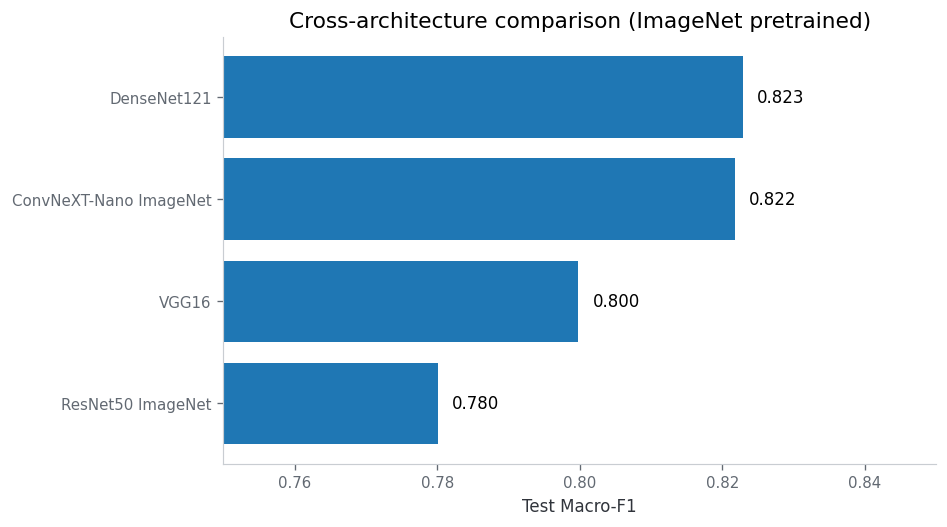

In [52]:
# Cross-architecture comparison (ImageNet pretrained only)

import matplotlib.pyplot as plt

# Keep only ImageNet-pretrained models
imagenet_model_keys = [
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "convnext_nano_imagenet",
]

cross_df = (
    summary_df[
        summary_df["Model Key"].isin(imagenet_model_keys)
    ]
    .sort_values("Macro-F1", ascending=False)
    .reset_index(drop=True)
)

# Plot
plt.figure(figsize=(8, 4.5))

bars = plt.barh(
    cross_df["Model"],
    cross_df["Macro-F1"],
)

plt.gca().invert_yaxis()

# Value labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.002,
        bar.get_y() + bar.get_height()/2,
        f"{width:.3f}",
        va="center",
        fontsize=10,
    )

plt.xlabel("Test Macro-F1")
plt.title("Cross-architecture comparison (ImageNet pretrained)")
plt.xlim(0.75, 0.85)

plt.tight_layout()
plt.show()



The figure compares the overall Macro-F1 of all ImageNet-pretrained architectures, isolating the effect of network architecture while keeping the pretraining strategy fixed.

**DenseNet121 achieves the highest Macro-F1 (0.8229), narrowly outperforming ConvNeXT-Nano ImageNet (0.8218).** Although the difference is small, it indicates that DenseNet121 provides the best overall classification performance under identical ImageNet pretraining.

**VGG16 ranks third despite having the largest model size, while ResNet50 ImageNet obtains the lowest Macro-F1 among the pretrained architectures.** This suggests that a larger number of parameters does not necessarily translate into better classification accuracy.

Overall, **network architecture has a noticeable impact on classification performance**, with DenseNet121 and ConvNeXT-Nano showing the strongest performance on the Galaxy10 dataset.

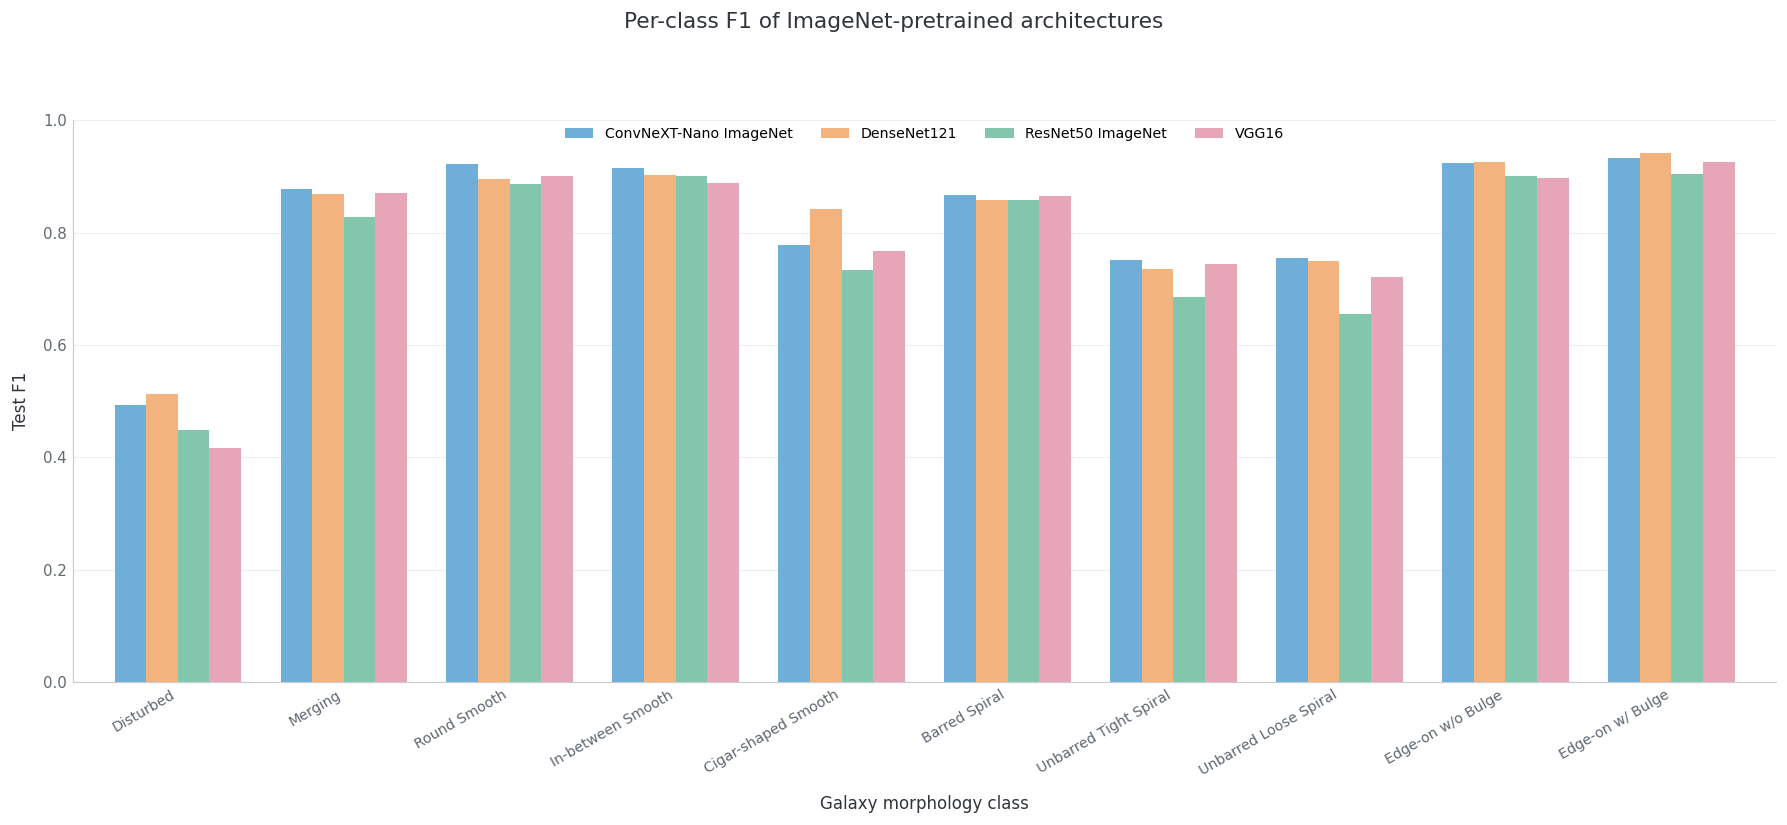

In [34]:
imagenet_per_class_models = [
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "convnext_nano_imagenet",
]

imagenet_per_class_df = per_class_df[
    per_class_df["Model Key"].isin(
        imagenet_per_class_models
    )
].copy()

imagenet_per_class_pivot = (
    imagenet_per_class_df
    .pivot(
        index="Class",
        columns="Model",
        values="F1",
    )
)

class_order = [
    "Disturbed",
    "Merging",
    "Round Smooth",
    "In-between Smooth",
    "Cigar-shaped Smooth",
    "Barred Spiral",
    "Unbarred Tight Spiral",
    "Unbarred Loose Spiral",
    "Edge-on w/o Bulge",
    "Edge-on w/ Bulge",
]

imagenet_per_class_pivot = (
    imagenet_per_class_pivot
    .reindex(class_order)
)

IMAGENET_COLOURS = [
    "#6FAED9",  # soft blue
    "#F2B37F",  # soft apricot
    "#82C6AE",  # soft mint
    "#E7A6B8",  # soft pink
]

axis = imagenet_per_class_pivot.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.76,
    color=IMAGENET_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "Per-class F1 of ImageNet-pretrained architectures",
    x=0.5,
    y=0.975,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Galaxy morphology class",
    labelpad=10,
)

axis.set_ylabel(
    "Test F1",
    labelpad=8,
)

axis.set_ylim(0, 1)

axis.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.tick_params(
    axis="x",
    rotation=30,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

for label in axis.get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_color("#5E6670")
    label.set_fontsize(8.5)

axis.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=4,
    frameon=False,
    fontsize=8.5,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    FIGURE_DIR / "imagenet_per_class_f1.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()



The figure compares the per-class F1 scores of all ImageNet-pretrained architectures to examine whether different network architectures perform consistently across different galaxy morphologies.

**All pretrained models achieve high F1 scores (>0.85) on relatively distinctive classes such as Round Smooth, In-between Smooth, Edge-on with Bulge, and Edge-on without Bulge.** This indicates that these galaxy morphologies are comparatively easier to recognize regardless of network architecture.

**The Disturbed class consistently produces the lowest F1 scores across all architectures, suggesting that it is the most challenging morphology in the Galaxy10 dataset.** This is likely because disturbed galaxies exhibit highly irregular structures and larger intra-class variation.

Among the ImageNet-pretrained models, **DenseNet121 achieves the best performance on Disturbed and Cigar-shaped Smooth galaxies, while ConvNeXT-Nano performs slightly better on Round Smooth, In-between Smooth, and spiral-related classes.** In contrast, **ResNet50 generally obtains lower per-class F1 scores than the other pretrained architectures.**

Overall, **although the overall Macro-F1 differences between architectures are relatively small, the per-class analysis reveals that different architectures have different strengths for specific galaxy morphologies.** This demonstrates that evaluating only the overall score may hide important class-level performance differences.

## 4. Pretraining Ablation

This analysis investigates the effect of **domain-specific pretraining**.

For each supported architecture, two pretrained versions are compared:

- ImageNet
- ZooBot

Only ResNet50 and ConvNeXT-Nano are included because ZooBot provides pretrained weights for these two architectures only.

**Since the network architecture is kept fixed while only the pretraining source changes, any performance difference can be attributed solely to the choice of pretrained weights rather than architectural changes.**



In [35]:
if not per_class_df.empty:
    hardest_classes_df = (
        per_class_df
        .sort_values(
            ["Model", "F1"],
            ascending=[True, True],
        )
        .groupby("Model")
        .head(3)
    )

    hardest_classes_df[
        [
            "Model",
            "Class",
            "Precision",
            "Recall",
            "F1",
            "Support",
        ]
    ].round(4)

In [36]:
pretraining_ablation_df = (
    build_pretraining_ablation_dataframe(results)
)

if pretraining_ablation_df.empty:
    print(
        "The ImageNet and Zoobot model pairs "
        "have not all been trained yet."
    )
else:
    display(pretraining_ablation_df.round(4))

,Architecture,ImageNet Accuracy,Zoobot Accuracy,Accuracy Difference,ImageNet Macro-F1,Zoobot Macro-F1,Macro-F1 Difference
0,ResNet50,0.8005,0.8720,0.0716,0.7801,0.8525,0.0724
1,ConvNeXT-Nano,0.8405,0.8828,0.0423,0.8218,0.8602,0.0384


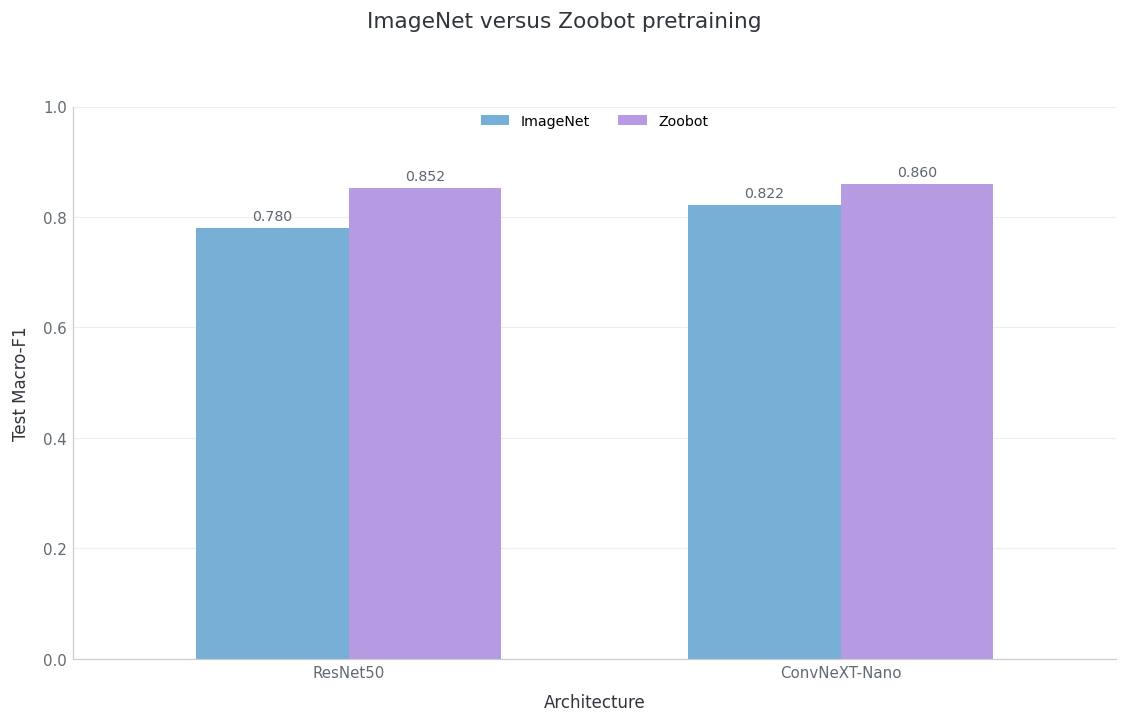

In [37]:
PRETRAINING_COLOURS = [
    "#78AFD6",  # ImageNet: soft blue
    "#B79BE2",  # Zoobot: soft pink
]

axis = pretraining_ablation_df.plot(
    x="Architecture",
    y=[
        "ImageNet Macro-F1",
        "Zoobot Macro-F1",
    ],
    kind="bar",
    figsize=(9.5, 6.2),
    width=0.62,
    color=PRETRAINING_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "ImageNet versus Zoobot pretraining",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Architecture",
    labelpad=8,
)

axis.set_ylabel(
    "Test Macro-F1",
    labelpad=8,
)

axis.set_ylim(0, 1)

axis.tick_params(
    axis="x",
    rotation=0,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

axis.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.legend(
    title=None,
    labels=[
        "ImageNet",
        "Zoobot",
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=8.5,
)

for container in axis.containers:
    axis.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8.5,
        color="#5E6670",
    )

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    FIGURE_DIR / "imagenet_vs_zoobot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

**ZooBot pretraining consistently improves Macro-F1 for both architectures.**

Specifically,
ResNet50 improves from 0.7801 to 0.8525 (+0.0724).
ConvNeXT-Nano improves from 0.8218 to 0.8602 (+0.0384).

**The larger improvement observed on ResNet50 suggests that domain-specific pretraining is particularly beneficial for architectures whose ImageNet initialization is less well aligned with galaxy morphology.**

In [38]:
pretraining_gain_df = (
    per_class_df[
        per_class_df["Model Key"].isin(
            [
                "resnet50_imagenet",
                "resnet50_zoobot",
                "convnext_nano_imagenet",
                "convnext_nano_zoobot",
            ]
        )
    ]
    .pivot(
        index="Class",
        columns="Model Key",
        values="F1",
    )
)

pretraining_gain_df = pd.DataFrame(
    {
        "ResNet50 Zoobot Gain": (
            pretraining_gain_df["resnet50_zoobot"]
            - pretraining_gain_df["resnet50_imagenet"]
        ),
        "ConvNeXT-Nano Zoobot Gain": (
            pretraining_gain_df["convnext_nano_zoobot"]
            - pretraining_gain_df["convnext_nano_imagenet"]
        ),
    }
)

pretraining_gain_df = (
    pretraining_gain_df
    .reindex(class_order)
)

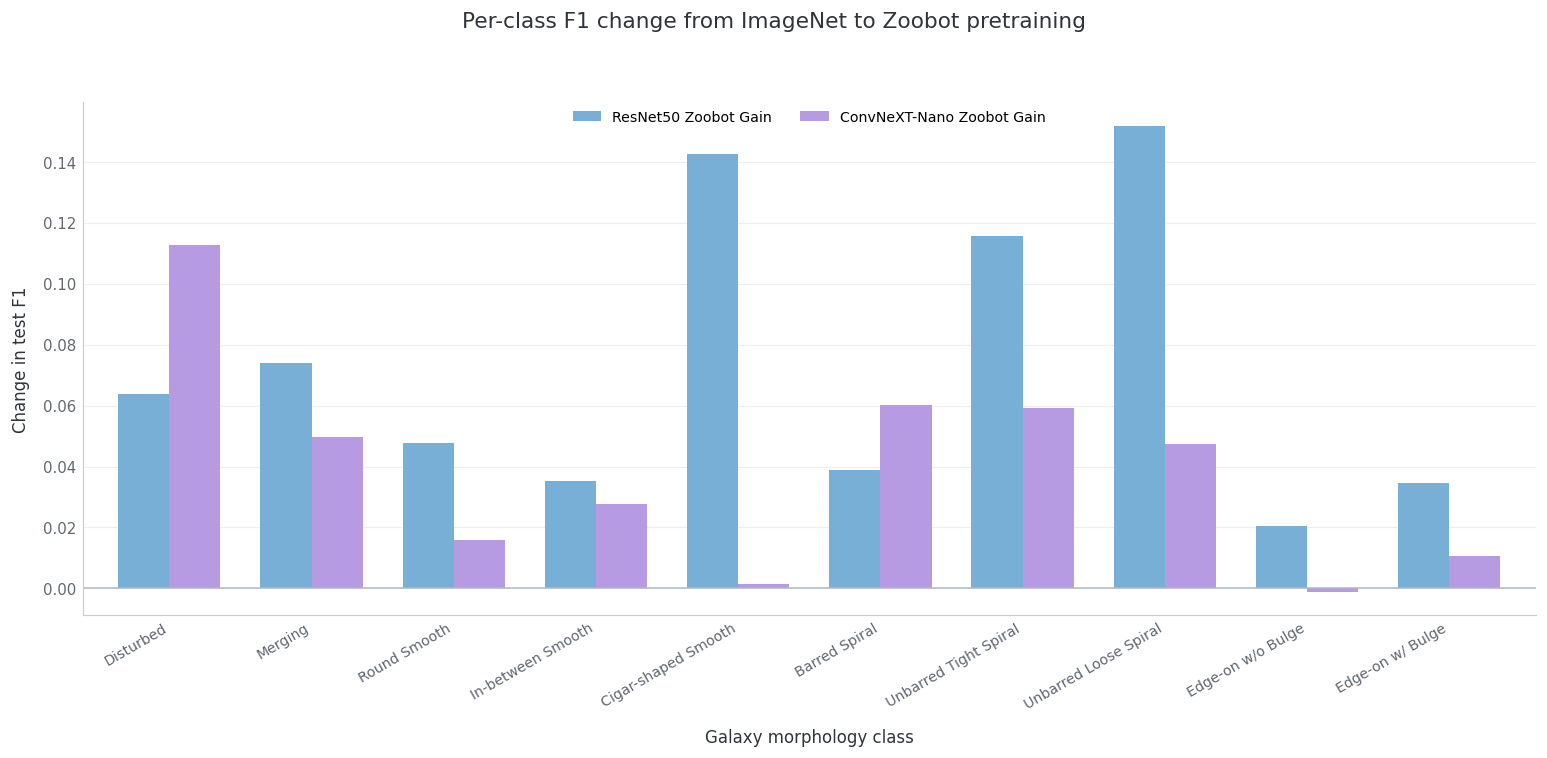

,ResNet50 Zoobot Gain,ConvNeXT-Nano Zoobot Gain
Class,,
Disturbed,0.0638,0.1128
Merging,0.0739,0.0498
Round Smooth,0.0476,0.0160
In-between Smooth,0.0353,0.0278
Cigar-shaped Smooth,0.1425,0.0014
Barred Spiral,0.0388,0.0604
Unbarred Tight Spiral,0.1155,0.0591
Unbarred Loose Spiral,0.1519,0.0474
Edge-on w/o Bulge,0.0204,-0.0011


In [39]:
GAIN_COLOURS = [
    "#78AFD6",  # ResNet50
    "#B79BE2",  # ConvNeXT-Nano
]

axis = pretraining_gain_df.plot(
    kind="bar",
    figsize=(13, 6.5),
    width=0.72,
    color=GAIN_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "Per-class F1 change from ImageNet to Zoobot pretraining",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color="#30343B",
)

axis.set_xlabel(
    "Galaxy morphology class",
    labelpad=10,
)

axis.set_ylabel(
    "Change in test F1",
    labelpad=8,
)

axis.axhline(
    y=0,
    color="#AEB8C2",
    linewidth=0.9,
    zorder=1,
)

axis.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

axis.tick_params(
    axis="x",
    rotation=30,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

for label in axis.get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_color("#5E6670")
    label.set_fontsize(8.5)

axis.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=8.5,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.92]
)

plt.savefig(
    FIGURE_DIR / "zoobot_per_class_f1_gain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

pretraining_gain_df.round(4)

**The class-level analysis further reveals that the performance gain is not uniformly distributed across all morphology classes.**

ResNet50 benefits substantially on several difficult classes, including

Cigar-shaped Smooth
Unbarred Loose Spiral
Unbarred Tight Spiral

while ConvNeXT-Nano shows **smaller but generally consistent improvements across most classes.**

These results indicate that **domain-specific pretraining mainly improves recognition of visually challenging galaxy morphologies rather than providing a uniform performance increase across all classes.**

**Overall, the ablation study demonstrates that domain-specific pretraining consistently improves classification performance, confirming that the performance gain arises from the pretrained representation rather than changes in network architecture.**

## 5. Confusion Matrix Analysis

Confusion matrices provide a class-level view of prediction behaviour.

The visualization is implemented in:

`src/evaluation/confusion_matrix.py`

For each model, both:

- raw confusion matrices
- row-normalized confusion matrices

are generated.

This analysis helps identify systematic misclassification patterns and reveals which galaxy morphology classes are visually similar and therefore difficult to distinguish.

### 5.1 Overall confusion matrices

To better understand model behaviour beyond overall accuracy, we analyse confusion matrices for all seven models.

Two versions are provided:

- **Raw confusion matrices**, showing the absolute number of predictions.
- **Row-normalized confusion matrices**, showing the proportion of predictions within each true class.

The normalized matrices are particularly useful because they remove the influence of class frequency and make class-level performance directly comparable across different models.

Across all architectures, most predictions lie on the diagonal, indicating generally strong classification performance. However, several visually similar galaxy morphologies still produce systematic misclassification patterns, motivating a closer investigation of specific error cases.

In [40]:
if not summary_df.empty:
    best_model_row = get_best_model(summary_df)

    best_model_key = best_model_row["Model Key"]
    best_model_name = best_model_row["Model"]

    print("Current best model:", best_model_name)
    print("Macro-F1:", round(best_model_row["Macro-F1"], 4))

Current best model: ConvNeXT-Nano Zoobot
Macro-F1: 0.8602


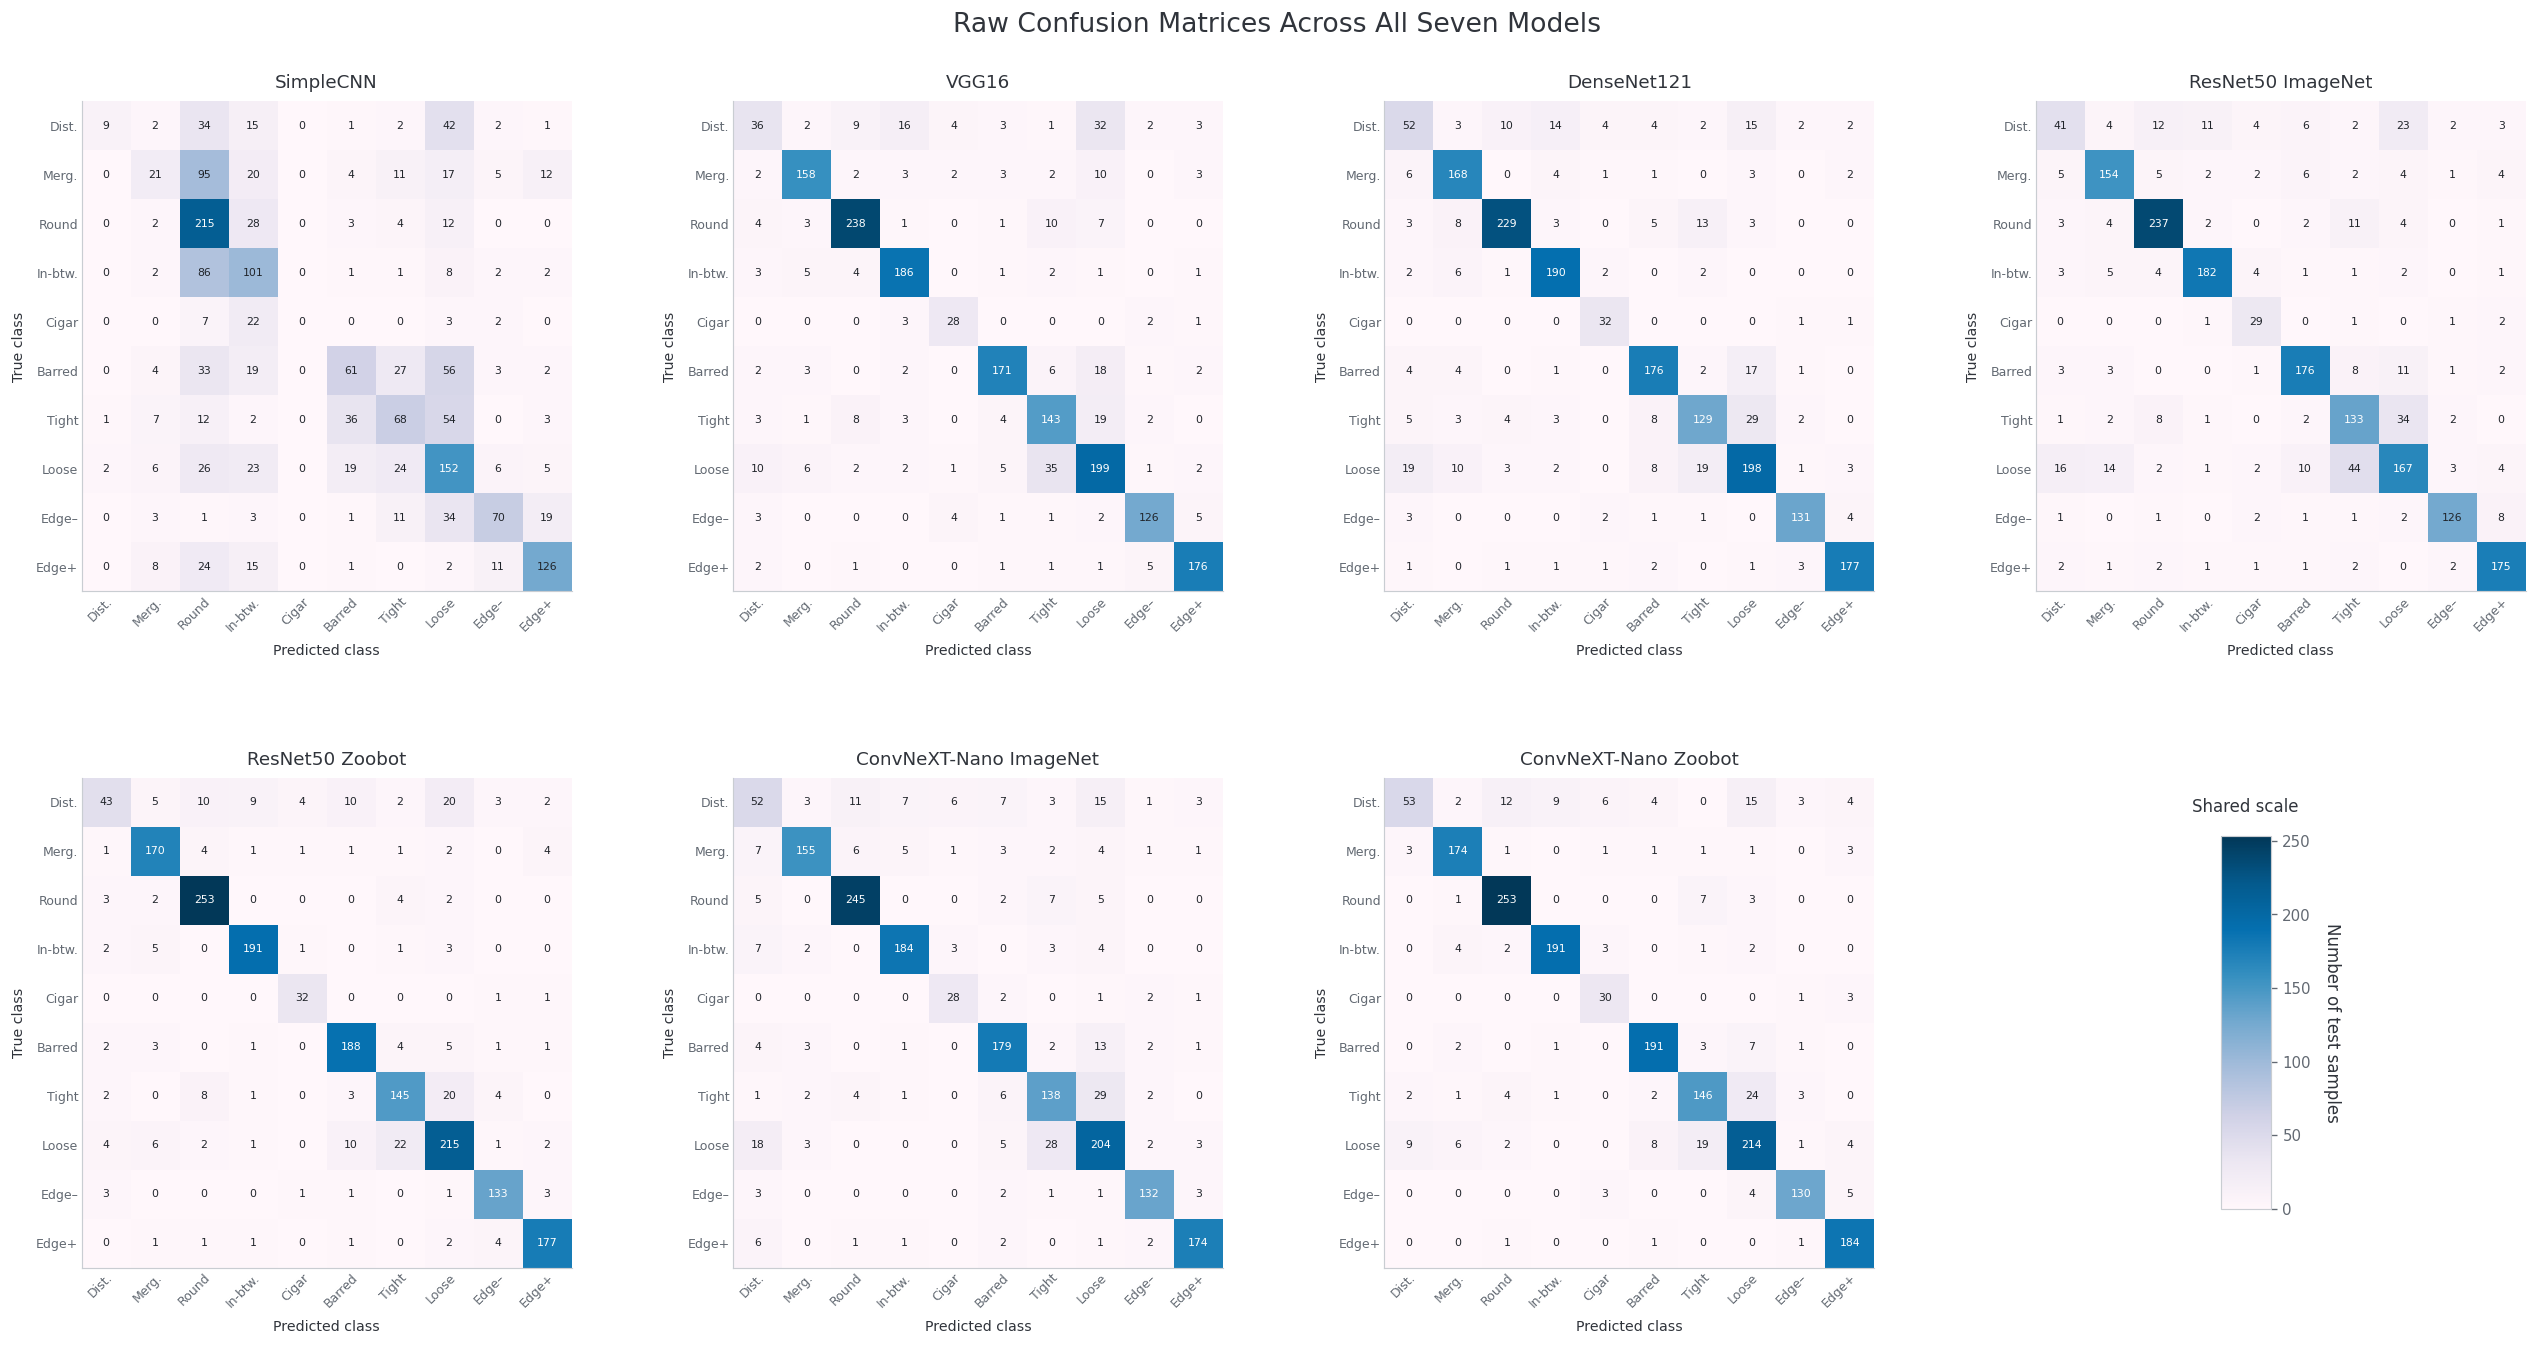

Saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/figures/all_models_raw_confusion_matrices.png


In [41]:
ALL_MODEL_KEYS = [
    "simplecnn",
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "resnet50_zoobot",
    "convnext_nano_imagenet",
    "convnext_nano_zoobot",
]

ALL_MODEL_DISPLAY_NAMES = {
    "simplecnn": "SimpleCNN",
    "vgg16": "VGG16",
    "densenet121": "DenseNet121",
    "resnet50_imagenet": "ResNet50 ImageNet",
    "resnet50_zoobot": "ResNet50 Zoobot",
    "convnext_nano_imagenet": "ConvNeXT-Nano ImageNet",
    "convnext_nano_zoobot": "ConvNeXT-Nano Zoobot",
}

SHORT_CLASS_NAMES = [
    "Dist.",
    "Merg.",
    "Round",
    "In-btw.",
    "Cigar",
    "Barred",
    "Tight",
    "Loose",
    "Edge–",
    "Edge+",
]


# Require all seven model results.
missing_models = [
    model_key
    for model_key in ALL_MODEL_KEYS
    if model_key not in results
]

if missing_models:
    raise ValueError(
        "Missing required model results: "
        + ", ".join(missing_models)
    )


# Read and validate matrices.
raw_matrices = {}

expected_shape = (
    len(CLASS_NAMES),
    len(CLASS_NAMES),
)

for model_key in ALL_MODEL_KEYS:
    if "confusion_matrix" not in results[model_key]:
        raise KeyError(
            f"Missing confusion_matrix for {model_key}."
        )

    matrix = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    if matrix.shape != expected_shape:
        raise ValueError(
            f"{model_key} has confusion matrix shape "
            f"{matrix.shape}; expected {expected_shape}."
        )

    raw_matrices[model_key] = matrix


global_max = max(
    matrix.max()
    for matrix in raw_matrices.values()
)


# Create 2 × 4 layout.
figure, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 11.5),
)

axes = axes.flatten()

image = None


for axis, model_key in zip(
    axes[:7],
    ALL_MODEL_KEYS,
):
    matrix = raw_matrices[model_key]

    image = axis.imshow(
        matrix,
        cmap="PuBu",
        interpolation="nearest",
        vmin=0,
        vmax=global_max,
        aspect="equal",
    )

    axis.set_box_aspect(1)

    axis.set_title(
        ALL_MODEL_DISPLAY_NAMES[model_key],
        fontsize=11,
        fontweight="normal",
        color="#30343B",
        pad=8,
    )

    axis.set_xticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_yticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_xticklabels(
        SHORT_CLASS_NAMES,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=7.5,
    )

    axis.set_yticklabels(
        SHORT_CLASS_NAMES,
        fontsize=7.5,
    )

    axis.set_xlabel(
        "Predicted class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.set_ylabel(
        "True class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.tick_params(
        axis="both",
        length=0,
        pad=2,
    )

    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[
                row_index,
                column_index
            ]

            axis.text(
                column_index,
                row_index,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=6.5,
                color=(
                    "white"
                    if value > global_max * 0.5
                    else "#20242A"
                ),
            )


# Use the eighth panel only for the colorbar.
colorbar_panel = axes[7]
colorbar_panel.axis("off")

colorbar_axis = colorbar_panel.inset_axes(
    [0.38, 0.12, 0.10, 0.76]
)

colorbar = figure.colorbar(
    image,
    cax=colorbar_axis,
)

colorbar.set_label(
    "Number of test samples",
    rotation=270,
    labelpad=18,
    fontsize=10,
)

colorbar_panel.text(
    0.43,
    0.94,
    "Shared scale",
    ha="center",
    va="center",
    fontsize=10,
    color="#30343B",
)


figure.suptitle(
    "Raw Confusion Matrices Across All Seven Models",
    fontsize=16,
    fontweight="normal",
    color="#30343B",
    y=0.985,
)

figure.subplots_adjust(
    left=0.045,
    right=0.975,
    top=0.92,
    bottom=0.075,
    wspace=0.30,
    hspace=0.38,
)


raw_output_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "all_models_raw_confusion_matrices.png"
)

raw_output_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

figure.savefig(
    raw_output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved to: {raw_output_path}")

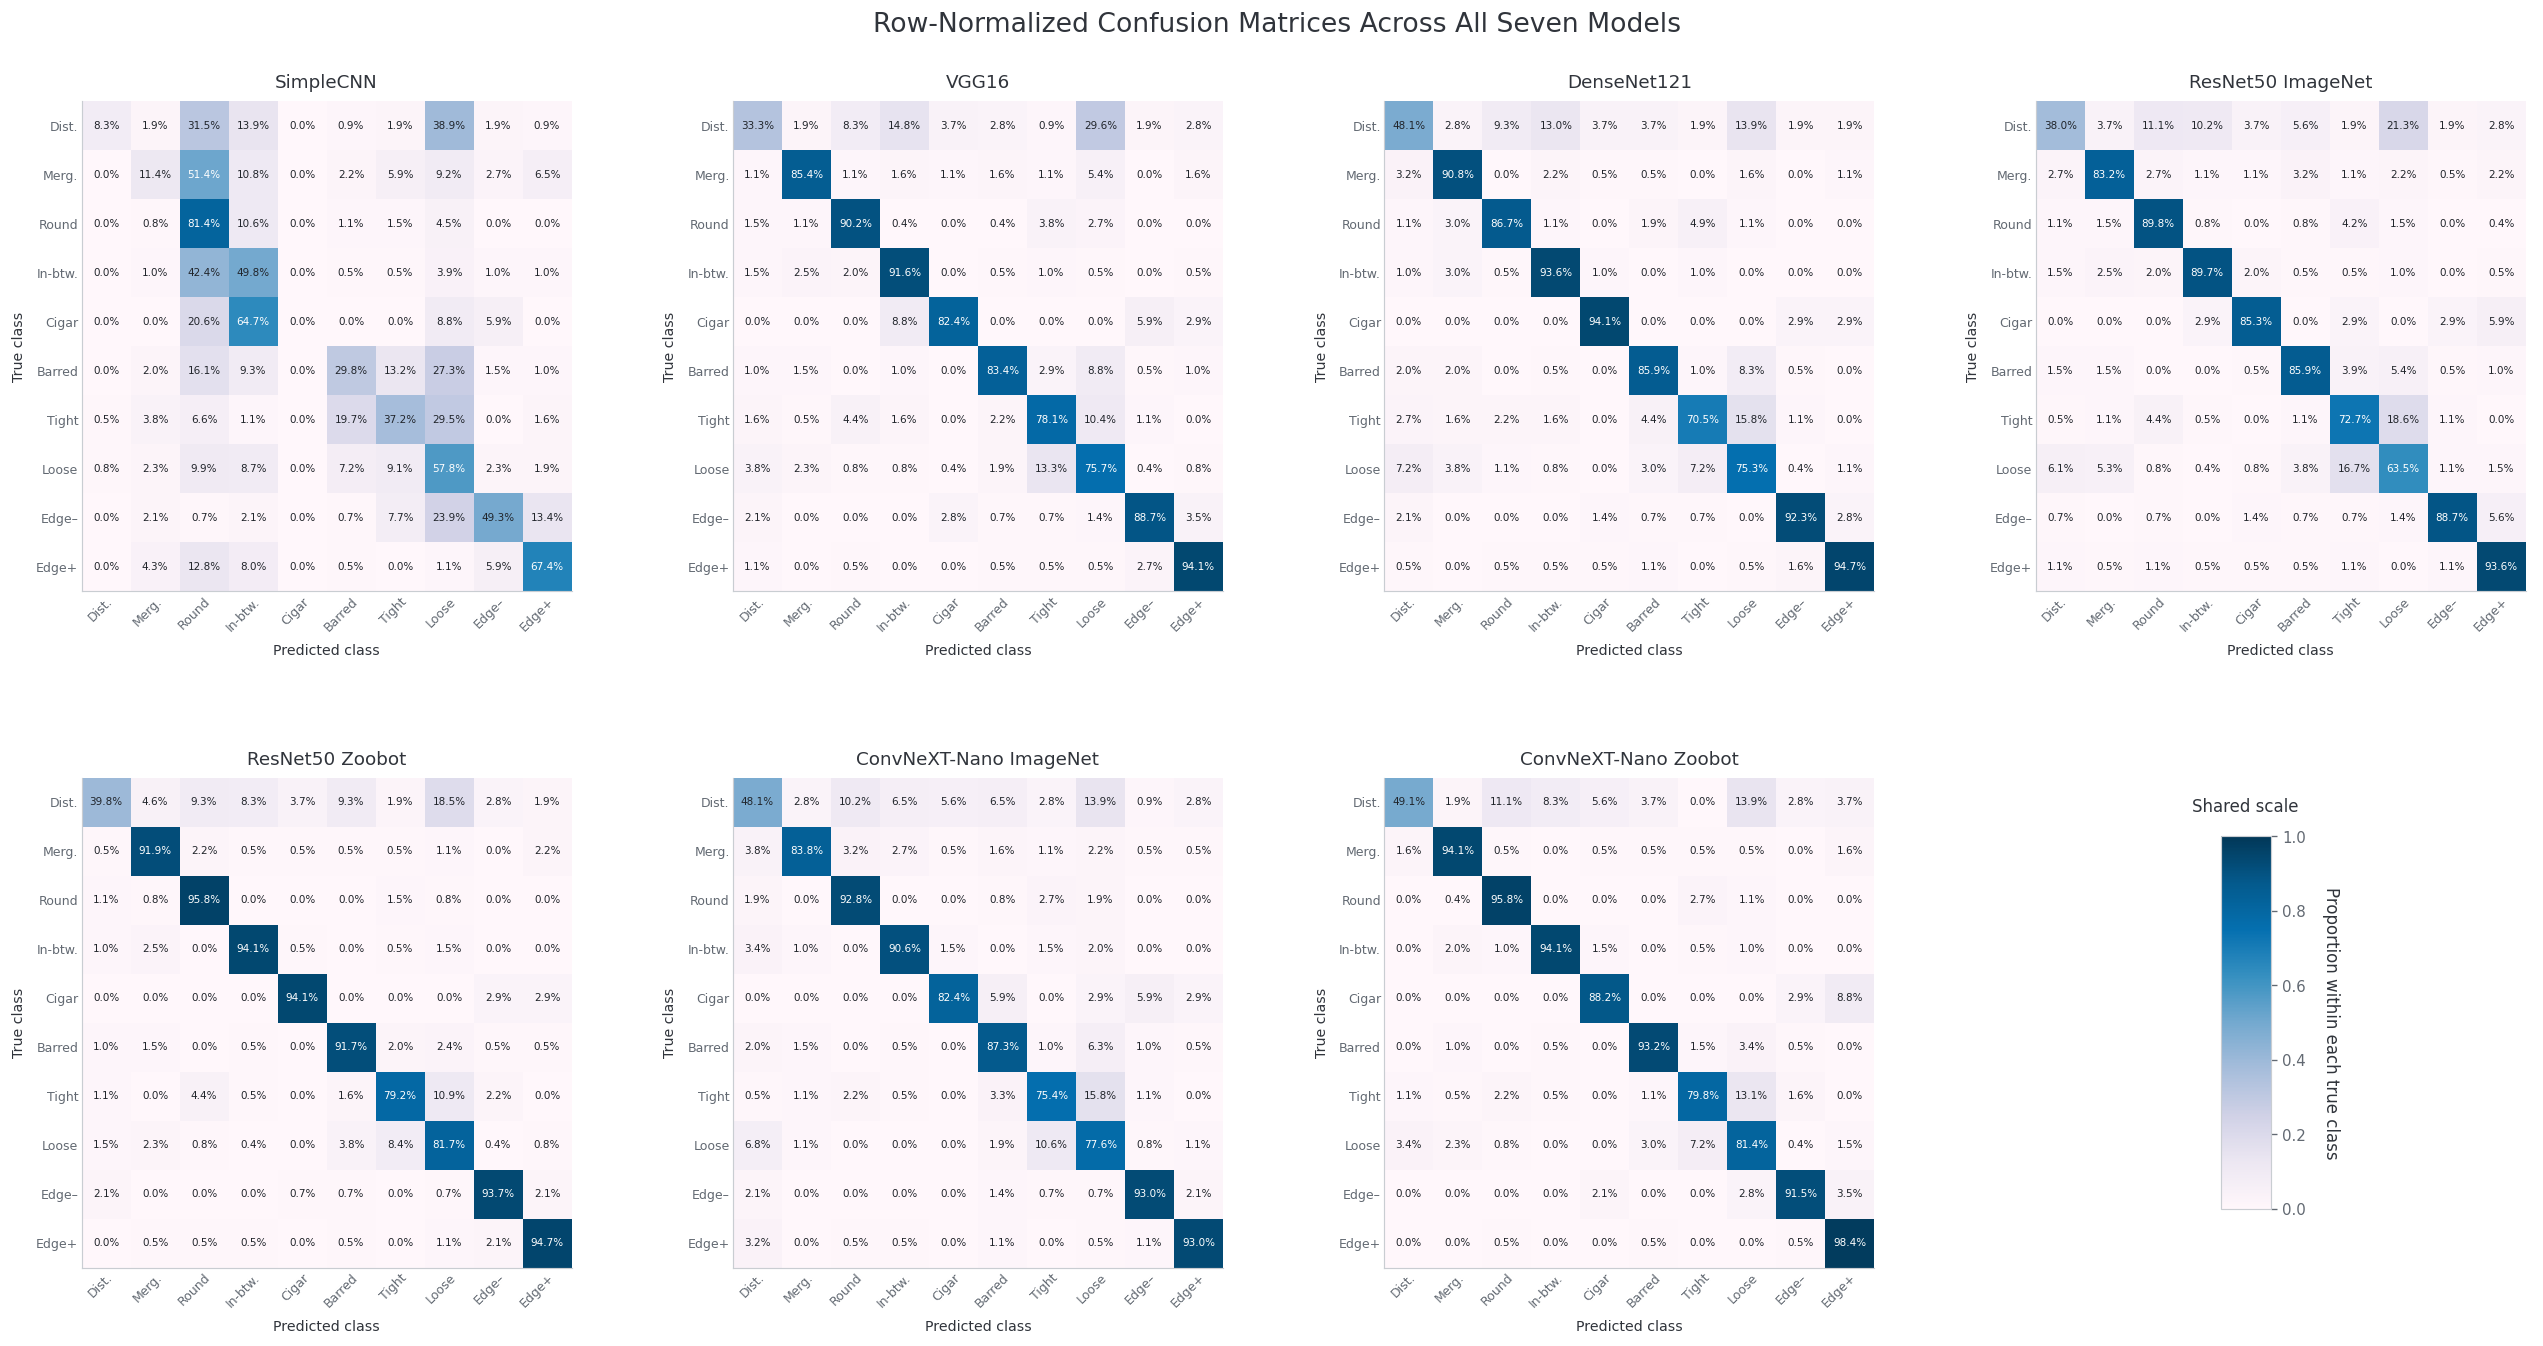

Saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/figures/all_models_normalized_confusion_matrices.png


In [42]:
ALL_MODEL_KEYS = [
    "simplecnn",
    "vgg16",
    "densenet121",
    "resnet50_imagenet",
    "resnet50_zoobot",
    "convnext_nano_imagenet",
    "convnext_nano_zoobot",
]

ALL_MODEL_DISPLAY_NAMES = {
    "simplecnn": "SimpleCNN",
    "vgg16": "VGG16",
    "densenet121": "DenseNet121",
    "resnet50_imagenet": "ResNet50 ImageNet",
    "resnet50_zoobot": "ResNet50 Zoobot",
    "convnext_nano_imagenet": "ConvNeXT-Nano ImageNet",
    "convnext_nano_zoobot": "ConvNeXT-Nano Zoobot",
}

SHORT_CLASS_NAMES = [
    "Dist.",
    "Merg.",
    "Round",
    "In-btw.",
    "Cigar",
    "Barred",
    "Tight",
    "Loose",
    "Edge–",
    "Edge+",
]


# Require all seven model results.
missing_models = [
    model_key
    for model_key in ALL_MODEL_KEYS
    if model_key not in results
]

if missing_models:
    raise ValueError(
        "Missing required model results: "
        + ", ".join(missing_models)
    )


# Read, validate and normalize matrices by true-class row.
normalized_matrices = {}

expected_shape = (
    len(CLASS_NAMES),
    len(CLASS_NAMES),
)

for model_key in ALL_MODEL_KEYS:
    if "confusion_matrix" not in results[model_key]:
        raise KeyError(
            f"Missing confusion_matrix for {model_key}."
        )

    raw_matrix = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    if raw_matrix.shape != expected_shape:
        raise ValueError(
            f"{model_key} has confusion matrix shape "
            f"{raw_matrix.shape}; expected {expected_shape}."
        )

    row_totals = raw_matrix.sum(
        axis=1,
        keepdims=True,
    )

    if np.any(row_totals == 0):
        empty_rows = np.where(
            row_totals.squeeze() == 0
        )[0]

        raise ValueError(
            f"{model_key} contains empty true-class rows: "
            f"{empty_rows.tolist()}."
        )

    normalized_matrices[model_key] = (
        raw_matrix / row_totals
    )


# Create 2 × 4 layout.
figure, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 11.5),
)

axes = axes.flatten()

image = None


for axis, model_key in zip(
    axes[:7],
    ALL_MODEL_KEYS,
):
    matrix = normalized_matrices[model_key]

    image = axis.imshow(
        matrix,
        cmap="PuBu",
        interpolation="nearest",
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    axis.set_box_aspect(1)

    axis.set_title(
        ALL_MODEL_DISPLAY_NAMES[model_key],
        fontsize=11,
        fontweight="normal",
        color="#30343B",
        pad=8,
    )

    axis.set_xticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_yticks(
        np.arange(len(SHORT_CLASS_NAMES))
    )

    axis.set_xticklabels(
        SHORT_CLASS_NAMES,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=7.5,
    )

    axis.set_yticklabels(
        SHORT_CLASS_NAMES,
        fontsize=7.5,
    )

    axis.set_xlabel(
        "Predicted class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.set_ylabel(
        "True class",
        fontsize=8.5,
        labelpad=6,
    )

    axis.tick_params(
        axis="both",
        length=0,
        pad=2,
    )

    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[
                row_index,
                column_index
            ]

            axis.text(
                column_index,
                row_index,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=6.2,
                color=(
                    "white"
                    if value > 0.5
                    else "#20242A"
                ),
            )


colorbar_panel = axes[7]
colorbar_panel.axis("off")

colorbar_axis = colorbar_panel.inset_axes(
    [0.38, 0.12, 0.10, 0.76]
)

colorbar = figure.colorbar(
    image,
    cax=colorbar_axis,
)

colorbar.set_label(
    "Proportion within each true class",
    rotation=270,
    labelpad=20,
    fontsize=10,
)

colorbar_panel.text(
    0.43,
    0.94,
    "Shared scale",
    ha="center",
    va="center",
    fontsize=10,
    color="#30343B",
)


figure.suptitle(
    "Row-Normalized Confusion Matrices Across All Seven Models",
    fontsize=16,
    fontweight="normal",
    color="#30343B",
    y=0.985,
)

figure.subplots_adjust(
    left=0.045,
    right=0.975,
    top=0.92,
    bottom=0.075,
    wspace=0.30,
    hspace=0.38,
)


normalized_output_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "all_models_normalized_confusion_matrices.png"
)

normalized_output_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

figure.savefig(
    normalized_output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved to: {normalized_output_path}"
)

### 5.2 Best baseline versus best overall model

To investigate how domain-specific pretraining changes prediction behaviour, we compare the row-normalized confusion matrices of the best ImageNet-pretrained model (DenseNet121) and the best overall model (ConvNeXT-Nano ZooBot).

Both models classify most galaxy types reliably, but the ZooBot-pretrained model exhibits a stronger diagonal pattern and fewer off-diagonal errors.

This indicates that the performance improvement is not simply reflected in a higher overall Macro-F1 score, but also in reduced confusion between visually similar galaxy morphologies.

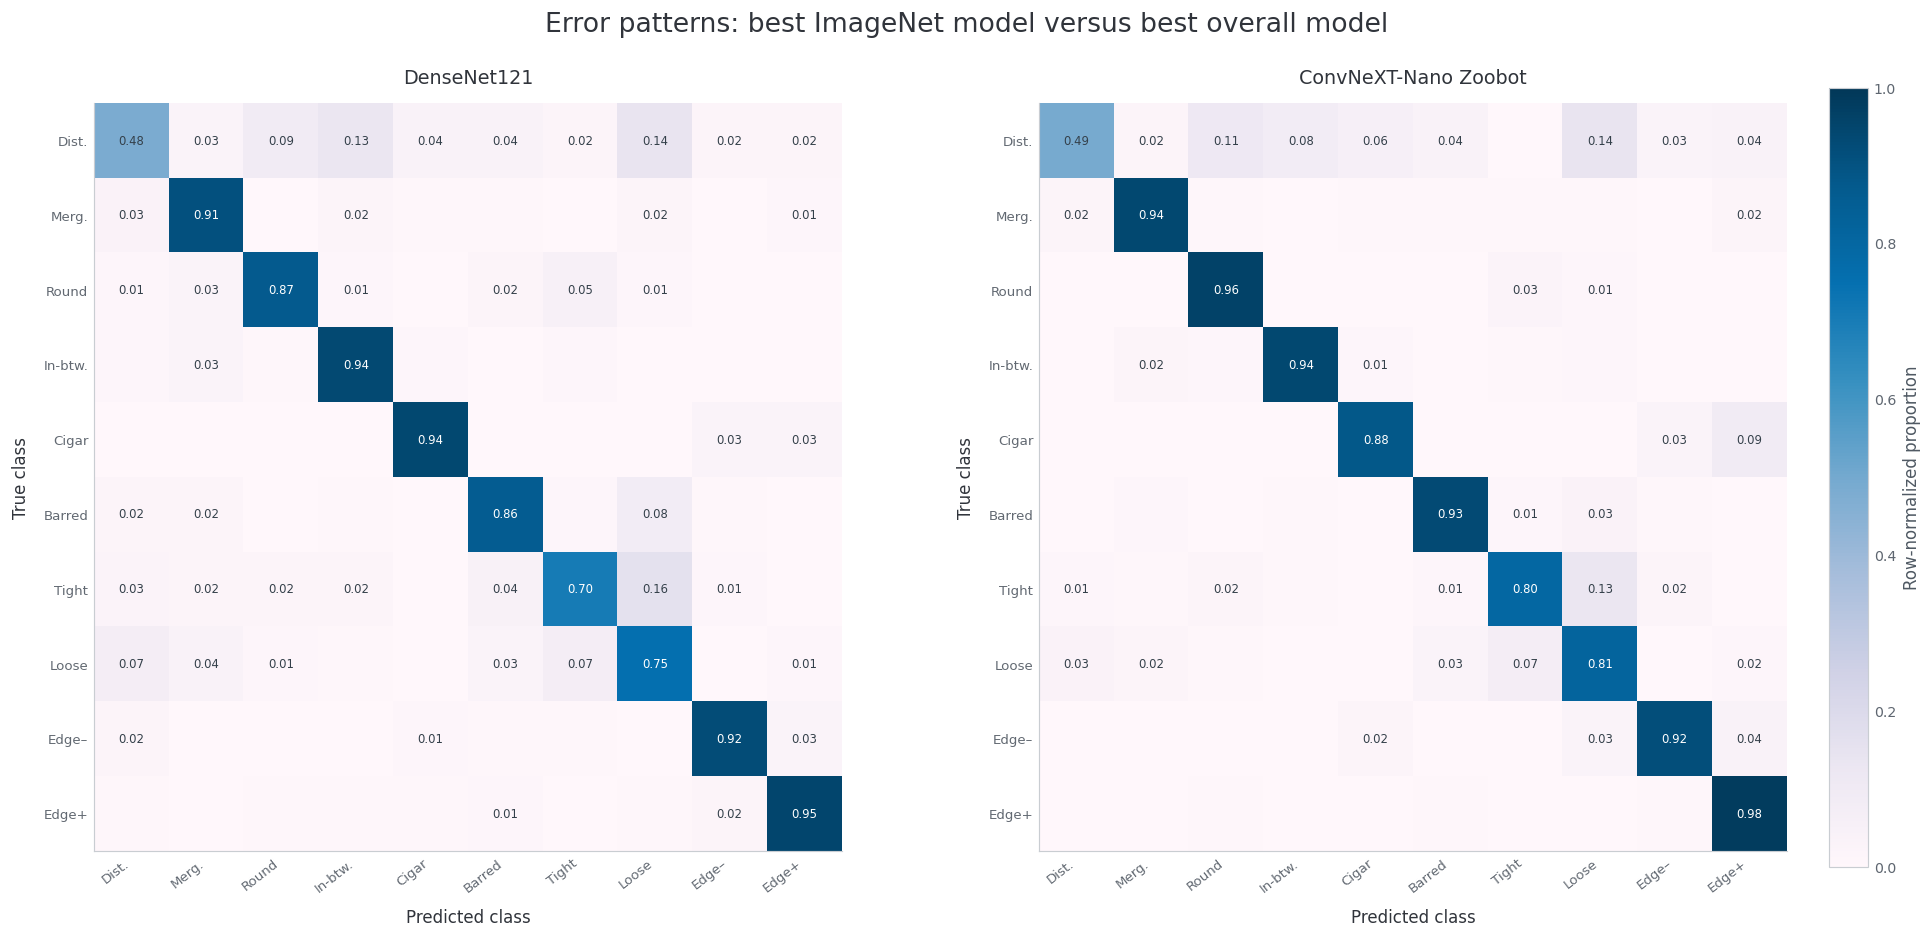

In [43]:
best_imagenet_row = (
    summary_df[
        summary_df["Pretraining"] == "ImageNet"
    ]
    .sort_values(
        "Macro-F1",
        ascending=False,
    )
    .iloc[0]
)

best_imagenet_key = best_imagenet_row[
    "Model Key"
]

best_imagenet_name = best_imagenet_row[
    "Model"
]

comparison_models = [
    (
        best_imagenet_key,
        best_imagenet_name,
    ),
    (
        best_model_key,
        best_model_name,
    ),
]

figure, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8),
    constrained_layout=True,
    gridspec_kw={
        "wspace": 0.12,
    },
)

for axis, (model_key, model_name) in zip(
    axes,
    comparison_models,
):
    confusion = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    row_sums = confusion.sum(
        axis=1,
        keepdims=True,
    )

    normalized_confusion = np.divide(
        confusion,
        row_sums,
        out=np.zeros_like(confusion),
        where=row_sums != 0,
    )

    image = axis.imshow(
        normalized_confusion,
        cmap="PuBu",
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    axis.set_title(
        model_name,
        pad=12,
        fontsize=11.5,
        fontweight="normal",
        color="#30343B",
    )

    axis.set_xlabel(
        "Predicted class",
        labelpad=8,
    )
    axis.set_ylabel(
        "True class",
        labelpad=8,
    )

    axis.set_xticks(
        range(len(SHORT_CLASS_NAMES))
    )
    axis.set_yticks(
        range(len(SHORT_CLASS_NAMES))
    )

    axis.set_xticklabels(
        SHORT_CLASS_NAMES,
        rotation=38,
        ha="right",
        fontsize=8,
    )

    axis.set_yticklabels(
        SHORT_CLASS_NAMES,
        fontsize=8,
    )

    axis.tick_params(
        axis="both",
        length=0,
    )

    for row_index in range(
        normalized_confusion.shape[0]
    ):
        for column_index in range(
            normalized_confusion.shape[1]
        ):
            value = normalized_confusion[
                row_index,
                column_index
            ]

            if value < 0.01:
                continue

            text_colour = (
                "white"
                if value >= 0.55
                else "#34404A"
            )

            axis.text(
                column_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color=text_colour,
            )

colour_bar = figure.colorbar(
    image,
    ax=axes,
    location="right",
    shrink=0.82,
    pad=0.025,
)

colour_bar.set_label(
    "Row-normalized proportion",
    color="#4F5963",
)

colour_bar.ax.tick_params(
    length=0,
    labelsize=8.5,
    colors="#5E6670",
)

figure.suptitle(
    "Error patterns: best ImageNet model versus best overall model",
    x=0.5,
    y=0.985,
    ha="center",
    fontsize=16,
    fontweight="normal",
    color="#30343B",
)

plt.savefig(
    FIGURE_DIR
    / "best_imagenet_vs_best_overall_confusion.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 5.3 Analysis of the most challenging class

Previous per-class analysis showed that **Disturbed galaxies** consistently achieve the lowest F1 scores across nearly all models.

To better understand these errors, we examine how samples belonging to the Disturbed class are classified by each architecture.

For every model, predictions are divided into three groups:

- Correctly classified as Disturbed.
- Misclassified as Unbarred Loose Spiral.
- Misclassified into all other classes.

The results reveal that Disturbed galaxies are frequently confused with Unbarred Loose Spiral galaxies, suggesting that these two morphologies share similar visual characteristics.

Compared with ImageNet-pretrained models, ZooBot-pretrained models correctly classify a larger proportion of Disturbed galaxies while reducing systematic confusion with spiral classes.

,Model Key,Model,Correct Disturbed,Disturbed → Loose Spiral,Disturbed → Other,Disturbed Support
0,simplecnn,SimpleCNN,0.0833,0.3889,0.5278,108
1,vgg16,VGG16,0.3333,0.2963,0.3704,108
2,densenet121,DenseNet121,0.4815,0.1389,0.3796,108
3,resnet50_imagenet,ResNet50\nImageNet,0.3796,0.2130,0.4074,108
4,resnet50_zoobot,ResNet50\nZoobot,0.3981,0.1852,0.4167,108
5,convnext_nano_imagenet,ConvNeXT-Nano\nImageNet,0.4815,0.1389,0.3796,108
6,convnext_nano_zoobot,ConvNeXT-Nano\nZoobot,0.4907,0.1389,0.3704,108


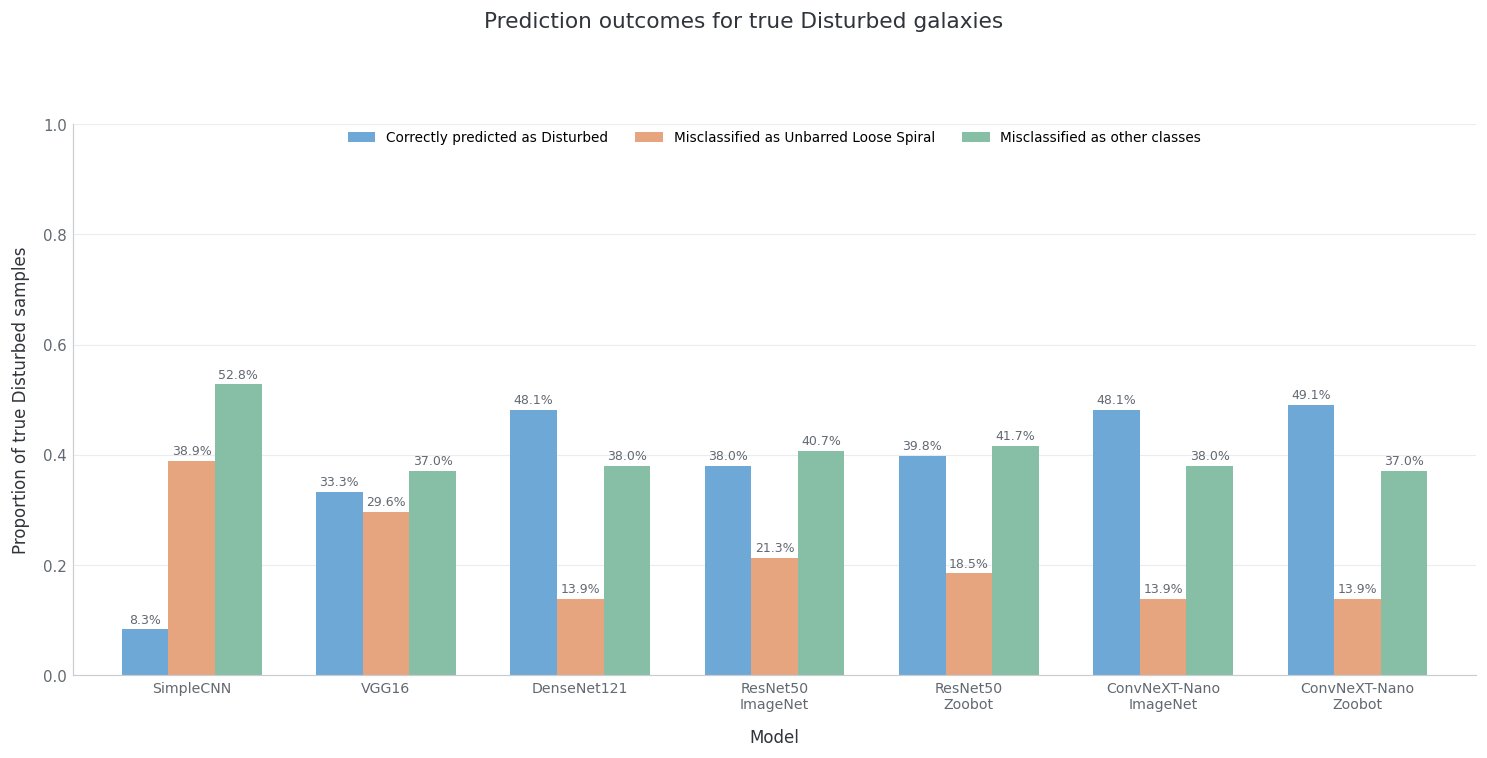

Saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/figures/disturbed_prediction_outcomes.png


In [44]:
DISTURBED_INDEX = CLASS_NAMES.index(
    "Disturbed"
)

LOOSE_SPIRAL_INDEX = CLASS_NAMES.index(
    "Unbarred Loose Spiral"
)

DISTURBED_MODEL_LABELS = {
    "simplecnn": "SimpleCNN",
    "vgg16": "VGG16",
    "densenet121": "DenseNet121",
    "resnet50_imagenet": "ResNet50\nImageNet",
    "resnet50_zoobot": "ResNet50\nZoobot",
    "convnext_nano_imagenet": (
        "ConvNeXT-Nano\nImageNet"
    ),
    "convnext_nano_zoobot": (
        "ConvNeXT-Nano\nZoobot"
    ),
}

disturbed_error_rows = []

for model_key in ALL_MODEL_KEYS:
    confusion = np.asarray(
        results[model_key]["confusion_matrix"],
        dtype=float,
    )

    disturbed_row = confusion[
        DISTURBED_INDEX
    ]

    disturbed_total = disturbed_row.sum()

    if disturbed_total <= 0:
        raise ValueError(
            f"{model_key} has no true Disturbed samples."
        )

    correct_rate = (
        disturbed_row[DISTURBED_INDEX]
        / disturbed_total
    )

    loose_spiral_rate = (
        disturbed_row[LOOSE_SPIRAL_INDEX]
        / disturbed_total
    )

    other_error_rate = (
        1.0
        - correct_rate
        - loose_spiral_rate
    )

    disturbed_error_rows.append(
        {
            "Model Key": model_key,
            "Model": DISTURBED_MODEL_LABELS[
                model_key
            ],
            "Correct Disturbed": correct_rate,
            "Disturbed → Loose Spiral": (
                loose_spiral_rate
            ),
            "Disturbed → Other": (
                other_error_rate
            ),
            "Disturbed Support": int(
                disturbed_total
            ),
        }
    )

disturbed_error_df = pd.DataFrame(
    disturbed_error_rows
)

display(
    disturbed_error_df.round(4)
)

plot_data = disturbed_error_df.set_index(
    "Model"
)[
    [
        "Correct Disturbed",
        "Disturbed → Loose Spiral",
        "Disturbed → Other",
    ]
]

axis = plot_data.plot(
    kind="bar",
    figsize=(12.5, 6.5),
    width=0.72,
    color=METRIC_COLOURS,
    edgecolor="none",
)

figure = axis.get_figure()

axis.set_title("")

figure.suptitle(
    "Prediction outcomes for true Disturbed galaxies",
    x=0.5,
    y=0.965,
    ha="center",
    fontsize=13,
    fontweight="normal",
    color=PALETTE["text"],
)

axis.set_xlabel(
    "Model",
    labelpad=10,
)

axis.set_ylabel(
    "Proportion of true Disturbed samples",
    labelpad=8,
)

axis.set_ylim(
    0,
    1,
)

axis.tick_params(
    axis="x",
    rotation=0,
    length=0,
)

axis.tick_params(
    axis="y",
    length=0,
)

axis.grid(
    axis="y",
    color=PALETTE["grid"],
    linewidth=0.7,
    alpha=0.85,
)

axis.set_axisbelow(True)

for label in axis.get_xticklabels():
    label.set_color(
        PALETTE["muted_text"]
    )
    label.set_fontsize(8.5)

axis.legend(
    title=None,
    labels=[
        "Correctly predicted as Disturbed",
        "Misclassified as Unbarred Loose Spiral",
        "Misclassified as other classes",
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False,
    fontsize=8.2,
)

for container in axis.containers:
    axis.bar_label(
        container,
        labels=[
            f"{value:.1%}"
            if value >= 0.025
            else ""
            for value in container.datavalues
        ],
        padding=2,
        fontsize=7.5,
        color=PALETTE["muted_text"],
    )

plt.tight_layout(
    rect=[0, 0, 1, 0.90]
)

disturbed_error_path = (
    FIGURE_DIR
    / "disturbed_prediction_outcomes.png"
)

figure.savefig(
    disturbed_error_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved to: {disturbed_error_path}"
)

In [45]:
import torch
from torch.utils.data import DataLoader

from src.baseline.train_baseline import (
    BATCH_SIZE,
    DEVICE,
    NUM_WORKERS,
    SEED,
    build_transforms,
)
from src.evaluation.gradcam import (
    load_trained_model,
    tensor_to_image,
)
from src.preprocessing.dataloader import (
    build_dataloaders,
)


DISTURBED_INDEX = CLASS_NAMES.index(
    "Disturbed"
)

LOOSE_SPIRAL_INDEX = CLASS_NAMES.index(
    "Unbarred Loose Spiral"
)


_, evaluation_transform = build_transforms()

_, _, original_test_loader = build_dataloaders(
    batch_size=BATCH_SIZE,
    train_ratio=0.8,
    val_ratio=0.1,
    test_ratio=0.1,
    random_state=SEED,
    num_workers=NUM_WORKERS,
    train_transform=evaluation_transform,
    val_transform=evaluation_transform,
    test_transform=evaluation_transform,
)

test_dataset = original_test_loader.dataset


ordered_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)


analysis_model = load_trained_model(
    best_model_key
)


all_true_labels = []
all_predicted_labels = []
all_confidences = []


analysis_model.eval()

with torch.no_grad():
    for images, labels in ordered_test_loader:
        images = images.to(
            DEVICE
        )

        logits = analysis_model(
            images
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        )

        confidences, predictions = (
            probabilities.max(dim=1)
        )

        all_true_labels.append(
            labels.cpu().numpy()
        )

        all_predicted_labels.append(
            predictions.cpu().numpy()
        )

        all_confidences.append(
            confidences.cpu().numpy()
        )


all_true_labels = np.concatenate(
    all_true_labels
)

all_predicted_labels = np.concatenate(
    all_predicted_labels
)

all_confidences = np.concatenate(
    all_confidences
)


if len(all_true_labels) != len(test_dataset):
    raise RuntimeError(
        "Prediction count does not match the test-dataset size."
    )


test_sample_indices = np.arange(
    len(test_dataset)
)


correct_disturbed_candidates = (
    test_sample_indices[
        (all_true_labels == DISTURBED_INDEX)
        & (
            all_predicted_labels
            == DISTURBED_INDEX
        )
    ]
)


incorrect_disturbed_candidates = (
    test_sample_indices[
        (all_true_labels == DISTURBED_INDEX)
        & (
            all_predicted_labels
            == LOOSE_SPIRAL_INDEX
        )
    ]
)


correct_loose_candidates = (
    test_sample_indices[
        (
            all_true_labels
            == LOOSE_SPIRAL_INDEX
        )
        & (
            all_predicted_labels
            == LOOSE_SPIRAL_INDEX
        )
    ]
)


print(
    "Best model:",
    best_model_key,
)

print(
    "Correct Disturbed candidates:",
    len(correct_disturbed_candidates),
)

print(
    "Disturbed → Loose Spiral candidates:",
    len(incorrect_disturbed_candidates),
)

print(
    "Correct Loose Spiral candidates:",
    len(correct_loose_candidates),
)

/root/.astroNN/datasets/Galaxy10_DECals.h5 was found!


Best model: convnext_nano_zoobot
Correct Disturbed candidates: 53
Disturbed → Loose Spiral candidates: 15
Correct Loose Spiral candidates: 214


### 5.4 Representative prediction examples

To further investigate model behaviour, representative test samples are selected from three categories:

- Correctly classified Disturbed galaxies.
- Disturbed galaxies misclassified as Unbarred Loose Spiral.
- Correctly classified Unbarred Loose Spiral galaxies.

These examples provide concrete cases for qualitative analysis and serve as the input for the Grad-CAM visualisations presented in the next section.

In [46]:
SAMPLES_PER_GROUP = 6
SAMPLE_SELECTION_SEED = 42

selection_rng = np.random.default_rng(
    SAMPLE_SELECTION_SEED
)


def select_sample_indices(
    candidate_indices,
    sample_count,
    group_name,
):
    candidate_indices = np.asarray(
        candidate_indices,
        dtype=int,
    )

    if len(candidate_indices) < sample_count:
        raise ValueError(
            f"{group_name} contains only "
            f"{len(candidate_indices)} samples; "
            f"{sample_count} were requested."
        )

    return np.sort(
        selection_rng.choice(
            candidate_indices,
            size=sample_count,
            replace=False,
        )
    )


selected_correct_disturbed = (
    select_sample_indices(
        correct_disturbed_candidates,
        SAMPLES_PER_GROUP,
        "Correct Disturbed",
    )
)

selected_incorrect_disturbed = (
    select_sample_indices(
        incorrect_disturbed_candidates,
        SAMPLES_PER_GROUP,
        "Disturbed → Loose Spiral",
    )
)

selected_correct_loose = (
    select_sample_indices(
        correct_loose_candidates,
        SAMPLES_PER_GROUP,
        "Correct Loose Spiral",
    )
)


selected_sample_indices = {
    "Correct Disturbed": (
        selected_correct_disturbed
    ),
    "Disturbed → Loose Spiral": (
        selected_incorrect_disturbed
    ),
    "Correct Loose Spiral": (
        selected_correct_loose
    ),
}


sample_selection_rows = []

for group_name, indices in (
    selected_sample_indices.items()
):
    for sample_index in indices:
        sample_selection_rows.append({
            "Group": group_name,
            "Sample Index": int(
                sample_index
            ),
            "True Class": CLASS_NAMES[
                int(
                    all_true_labels[
                        sample_index
                    ]
                )
            ],
            "Predicted Class": CLASS_NAMES[
                int(
                    all_predicted_labels[
                        sample_index
                    ]
                )
            ],
            "Prediction Confidence": float(
                all_confidences[
                    sample_index
                ]
            ),
        })


sample_selection_df = pd.DataFrame(
    sample_selection_rows
)

display(
    sample_selection_df.round(4)
)

,Group,Sample Index,True Class,Predicted Class,Prediction Confidence
0,Correct Disturbed,258,Disturbed,Disturbed,0.9361
1,Correct Disturbed,840,Disturbed,Disturbed,0.9560
2,Correct Disturbed,1057,Disturbed,Disturbed,0.8677
3,Correct Disturbed,1258,Disturbed,Disturbed,0.2878
4,Correct Disturbed,1542,Disturbed,Disturbed,0.6790
5,Correct Disturbed,1756,Disturbed,Disturbed,0.9554
6,Disturbed → Loose Spiral,950,Disturbed,Unbarred Loose Spiral,0.9819
7,Disturbed → Loose Spiral,956,Disturbed,Unbarred Loose Spiral,0.6741
8,Disturbed → Loose Spiral,1065,Disturbed,Unbarred Loose Spiral,0.5737
9,Disturbed → Loose Spiral,1346,Disturbed,Unbarred Loose Spiral,0.9197


## 6. Grad-CAM Visualization -- the Interpretability Analysis

To improve model interpretability, Grad-CAM is applied to visualize the image regions contributing most to each prediction.

The implementation is provided in:

`src/evaluation/gradcam.py`

For each selected test image, the script:

1. rebuilds the trained model;
2. loads the saved checkpoint;
3. computes Grad-CAM using the final convolutional layer;
4. generates:

- original image
- Grad-CAM heatmap
- overlay visualization

These visual explanations help verify whether the models focus on meaningful galaxy structures rather than irrelevant image regions.

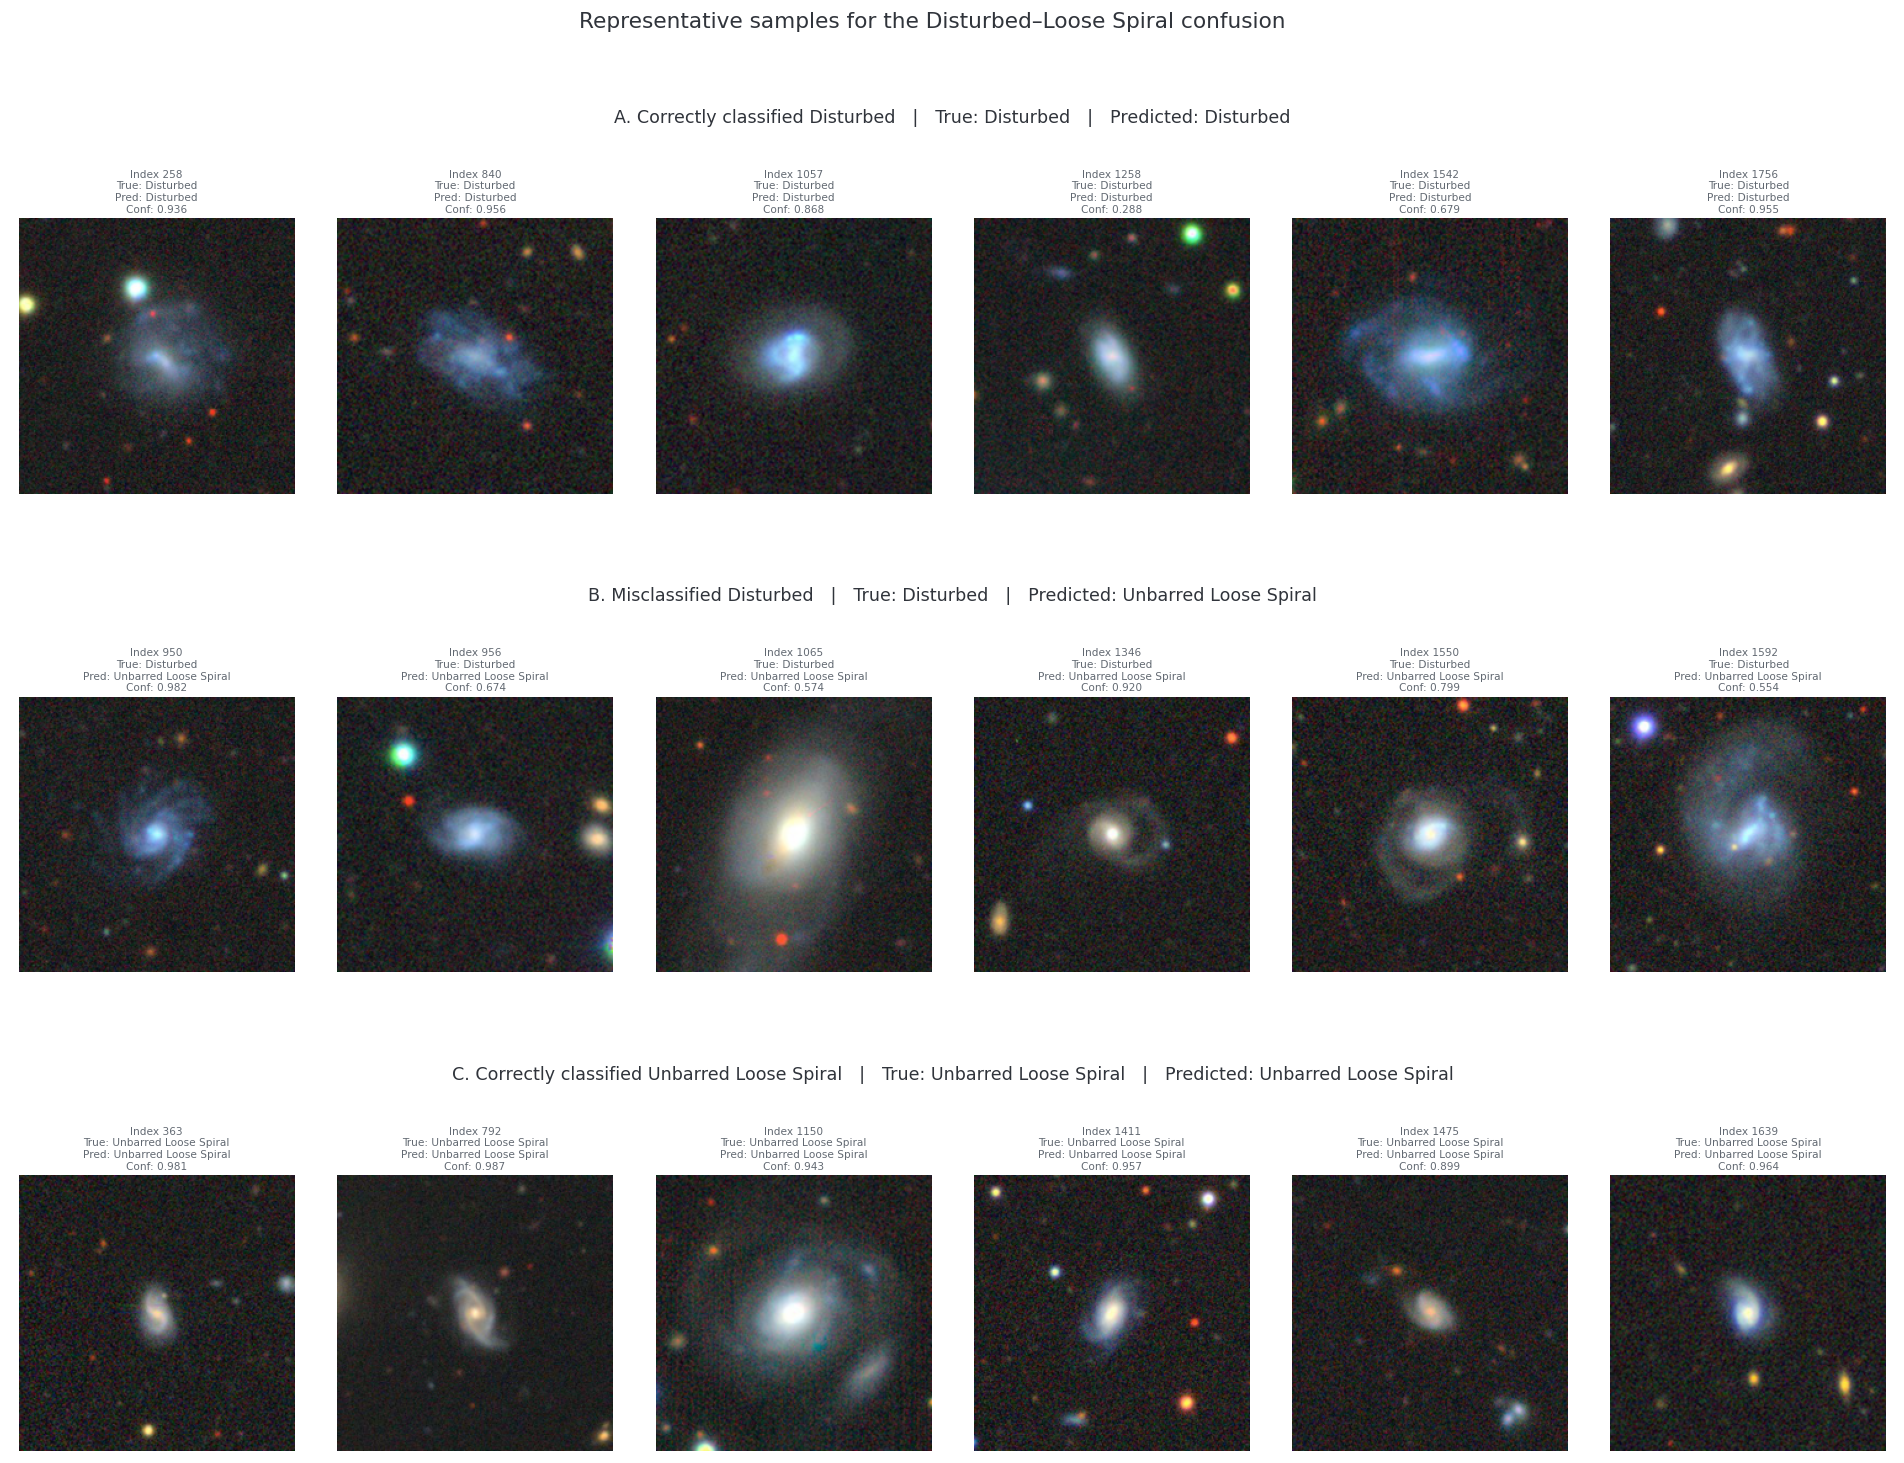

Saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/figures/disturbed_loose_spiral_sample_montage.png


In [47]:
from matplotlib.gridspec import GridSpec


group_definitions = [
    {
        "title": (
            "A. Correctly classified Disturbed"
            "   |   True: Disturbed"
            "   |   Predicted: Disturbed"
        ),
        "indices": selected_correct_disturbed,
    },
    {
        "title": (
            "B. Misclassified Disturbed"
            "   |   True: Disturbed"
            "   |   Predicted: Unbarred Loose Spiral"
        ),
        "indices": selected_incorrect_disturbed,
    },
    {
        "title": (
            "C. Correctly classified Unbarred Loose Spiral"
            "   |   True: Unbarred Loose Spiral"
            "   |   Predicted: Unbarred Loose Spiral"
        ),
        "indices": selected_correct_loose,
    },
]


figure = plt.figure(
    figsize=(16.5, 12.5),
)

grid = GridSpec(
    nrows=6,
    ncols=SAMPLES_PER_GROUP,
    figure=figure,
    height_ratios=[
        0.55,
        1.0,
        0.55,
        1.0,
        0.55,
        1.0,
    ],
    hspace=0.12,
    wspace=0.10,
)


for group_index, group in enumerate(
    group_definitions
):
    title_row = group_index * 2
    image_row = title_row + 1

    title_axis = figure.add_subplot(
        grid[
            title_row,
            :,
        ]
    )

    title_axis.text(
        0.5,
        0.5,
        group["title"],
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="normal",
        color=PALETTE["text"],
    )

    title_axis.axis(
        "off"
    )

    for column_index, sample_index in enumerate(
        group["indices"]
    ):
        axis = figure.add_subplot(
            grid[
                image_row,
                column_index,
            ]
        )

        image_tensor, true_label = (
            test_dataset[
                int(sample_index)
            ]
        )

        display_image = tensor_to_image(
            image_tensor.unsqueeze(0)
        )

        predicted_label = int(
            all_predicted_labels[
                sample_index
            ]
        )

        confidence = float(
            all_confidences[
                sample_index
            ]
        )

        axis.imshow(
            display_image
        )

        axis.set_title(
            f"Index {sample_index}\n"
            f"True: {CLASS_NAMES[int(true_label)]}\n"
            f"Pred: {CLASS_NAMES[predicted_label]}\n"
            f"Conf: {confidence:.3f}",
            fontsize=6.3,
            fontweight="normal",
            color=PALETTE["muted_text"],
            pad=4,
        )

        axis.axis(
            "off"
        )


figure.suptitle(
    "Representative samples for the "
    "Disturbed–Loose Spiral confusion",
    x=0.5,
    y=0.985,
    fontsize=13,
    fontweight="normal",
    color=PALETTE["text"],
)


figure.subplots_adjust(
    left=0.035,
    right=0.985,
    top=0.965,
    bottom=0.025,
)


sample_montage_path = (
    FIGURE_DIR
    / "disturbed_loose_spiral_sample_montage.png"
)

figure.savefig(
    sample_montage_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved to: {sample_montage_path}"
)

**A. Correctly classified Disturbed galaxies**

These examples are correctly recognized as **Disturbed** galaxies.

They serve as reference cases for interpreting what visual structures the model uses when making correct predictions.

**B. Disturbed galaxies misclassified as Unbarred Loose Spiral**

These examples illustrate the dominant confusion identified in the confusion matrix.

Although the galaxies contain disturbed structures, they also exhibit spiral-like morphology and bright central regions, making them visually similar to the Unbarred Loose Spiral class.

**C. Correctly classified Unbarred Loose Spiral galaxies**

These images represent typical loose spiral galaxies with relatively regular spiral structures.

They are used as reference examples to compare with the misclassified Disturbed galaxies.

In [48]:
gradcam_sample_indices = {
    "Correct Disturbed": int(
        selected_correct_disturbed[0]
    ),
    "Disturbed → Loose Spiral": int(
        selected_incorrect_disturbed[0]
    ),
    "Correct Loose Spiral": int(
        selected_correct_loose[0]
    ),
}

gradcam_sample_indices

{'Correct Disturbed': 258,
 'Disturbed → Loose Spiral': 950,
 'Correct Loose Spiral': 363}


Correct Disturbed: test sample 258
/root/.astroNN/datasets/Galaxy10_DECals.h5 was found!


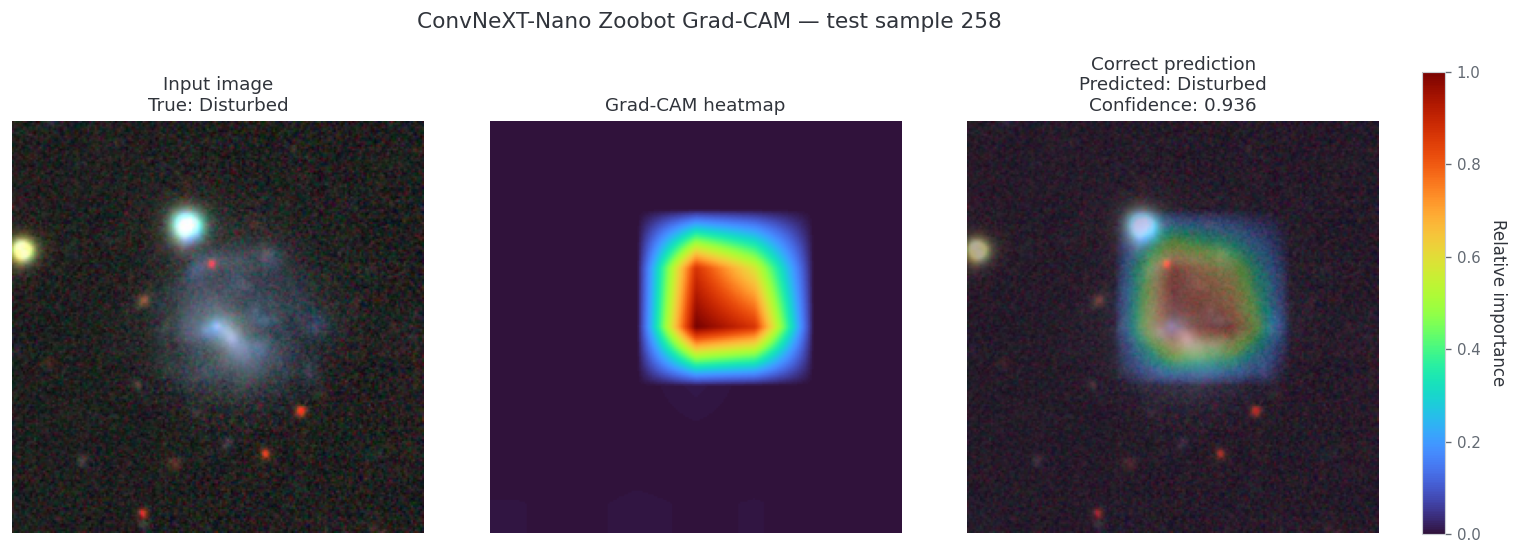


Disturbed → Loose Spiral: test sample 950
/root/.astroNN/datasets/Galaxy10_DECals.h5 was found!


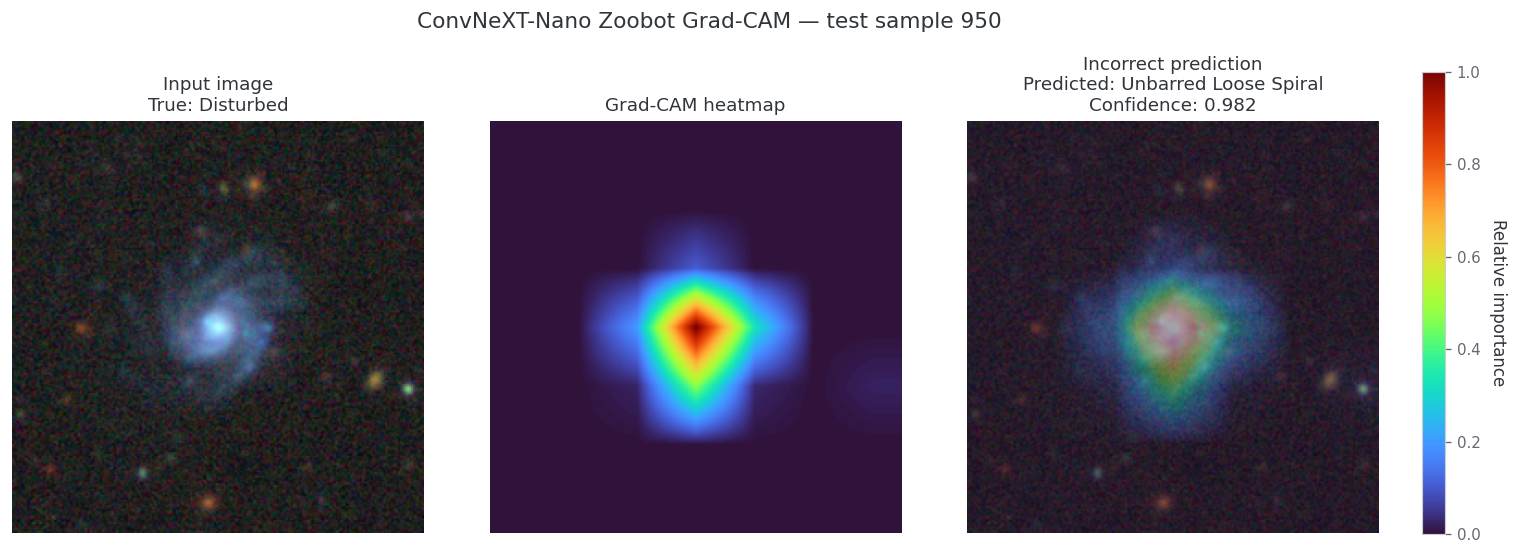


Correct Loose Spiral: test sample 363
/root/.astroNN/datasets/Galaxy10_DECals.h5 was found!


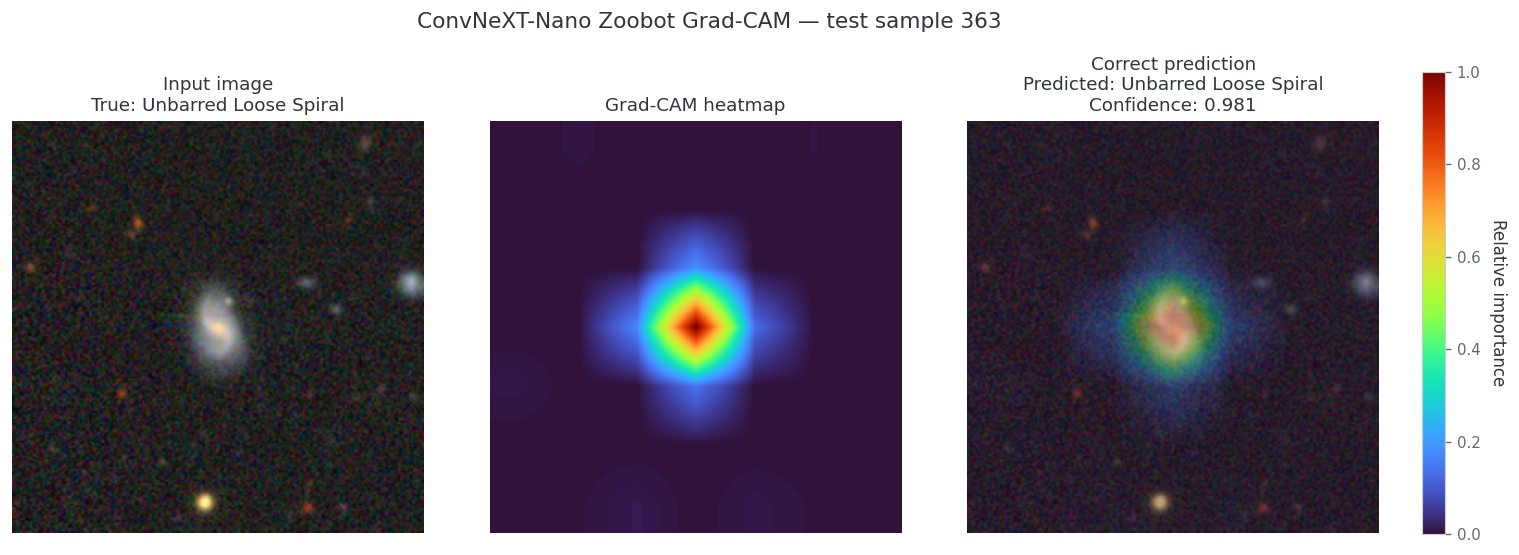

,Group,Model,Sample Index,True Class,Predicted Class,Prediction Confidence,Grad-CAM Target,Correct,Output Path
0,Correct Disturbed,convnext_nano_zoobot,258,Disturbed,Disturbed,0.936093,Disturbed,True,/content/COMP9444-Galaxy-Morphology-Classifica...
1,Disturbed → Loose Spiral,convnext_nano_zoobot,950,Disturbed,Unbarred Loose Spiral,0.981896,Unbarred Loose Spiral,False,/content/COMP9444-Galaxy-Morphology-Classifica...
2,Correct Loose Spiral,convnext_nano_zoobot,363,Unbarred Loose Spiral,Unbarred Loose Spiral,0.980501,Unbarred Loose Spiral,True,/content/COMP9444-Galaxy-Morphology-Classifica...


In [49]:
from IPython.display import display
from src.evaluation.gradcam import (
    generate_gradcam,
)


gradcam_comparison_results = []


for group_name, sample_index in (
    gradcam_sample_indices.items()
):
    print(
        f"\n{group_name}: "
        f"test sample {sample_index}"
    )

    result = generate_gradcam(
        model_name=best_model_key,
        sample_index=sample_index,
        target_class=None,
        save=True,
        return_figure=True,
    )

    display(
        result["figure"]
    )

    gradcam_comparison_results.append({
        "Group": group_name,
        "Model": result[
            "model_name"
        ],
        "Sample Index": result[
            "sample_index"
        ],
        "True Class": result[
            "true_class"
        ],
        "Predicted Class": result[
            "predicted_class"
        ],
        "Prediction Confidence": result[
            "predicted_confidence"
        ],
        "Grad-CAM Target": result[
            "target_class"
        ],
        "Correct": result[
            "correct"
        ],
        "Output Path": str(
            result[
                "output_path"
            ]
        ),
    })

    plt.close(
        result["figure"]
    )


gradcam_comparison_df = pd.DataFrame(
    gradcam_comparison_results
)

display(
    gradcam_comparison_df
)

**A. Correctly classified Disturbed galaxy**

The Grad-CAM activation is concentrated on the galaxy itself, particularly around the central disturbed morphology.

Very little attention is assigned to the background, indicating that the model bases its decision on meaningful galaxy structures rather than irrelevant image regions.

**B. Misclassified Disturbed galaxy**

Although the Grad-CAM still focuses on the galaxy rather than the background, the strongest activation is concentrated on the bright central region and spiral-like structure.

The weaker emphasis on the disturbed outer morphology may explain why the model predicts this sample as **Unbarred Loose Spiral** instead of **Disturbed**.


**C. Correctly classified Unbarred Loose Spiral galaxy**

The activation is concentrated on the bright central bulge and surrounding spiral structure.

These are characteristic features of loose spiral galaxies, suggesting that the model has learned meaningful morphology-related representations for this class.



**In summary,
The Grad-CAM visualizations demonstrate that the model generally attends to the galaxy itself rather than the surrounding background.**

For correctly classified examples, the attention maps align well with characteristic morphological structures.

For misclassified Disturbed galaxies, the model still focuses on the galaxy but places greater emphasis on the bright central region and spiral features than on the irregular disturbed structures, providing an explanation for the confusion observed in the confusion matrix analysis.

## 7. Evaluation Summary

Finally, all evaluation outputs are automatically exported.

Generated files include:

- model comparison tables
- per-class evaluation tables
- confusion matrix figures
- Grad-CAM visualizations
- summary CSV files

These outputs are directly used in the project report and presentation.

In [50]:
SUMMARY_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "summary"
)

SUMMARY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

summary_df.to_csv(
    SUMMARY_DIR / "all_models_summary.csv",
    index=False,
)

per_class_df.to_csv(
    SUMMARY_DIR / "per_class_metrics.csv",
    index=False,
)

pretraining_ablation_df.to_csv(
    SUMMARY_DIR / "pretraining_ablation.csv",
    index=False,
)

pretraining_gain_df.to_csv(
    SUMMARY_DIR / "pretraining_per_class_gain.csv",
    index=True,
)

disturbed_error_df.to_csv(
    SUMMARY_DIR / "disturbed_prediction_outcomes.csv",
    index=False,
)

sample_selection_df.to_csv(
    SUMMARY_DIR / "disturbed_sample_selection.csv",
    index=False,
)

gradcam_comparison_df.to_csv(
    SUMMARY_DIR / "disturbed_gradcam_comparison.csv",
    index=False,
)

print(
    "All-model summary saved to:",
    SUMMARY_DIR / "all_models_summary.csv",
)

print(
    "Per-class metrics saved to:",
    SUMMARY_DIR / "per_class_metrics.csv",
)

print(
    "Pretraining ablation saved to:",
    SUMMARY_DIR / "pretraining_ablation.csv",
)

print(
    "Per-class pretraining gain saved to:",
    SUMMARY_DIR / "pretraining_per_class_gain.csv",
)
print(
    "Disturbed prediction outcomes saved to:",
    SUMMARY_DIR / "disturbed_prediction_outcomes.csv",
)

print(
    "Disturbed sample selection saved to:",
    SUMMARY_DIR / "disturbed_sample_selection.csv",
)

print(
    "Disturbed Grad-CAM comparison saved to:",
    SUMMARY_DIR / "disturbed_gradcam_comparison.csv",
)

All-model summary saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/all_models_summary.csv
Per-class metrics saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/per_class_metrics.csv
Pretraining ablation saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/pretraining_ablation.csv
Per-class pretraining gain saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/pretraining_per_class_gain.csv
Disturbed prediction outcomes saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/disturbed_prediction_outcomes.csv
Disturbed sample selection saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/disturbed_sample_selection.csv
Disturbed Grad-CAM comparison saved to: /content/COMP9444-Galaxy-Morphology-Classification/outputs/summary/disturbed_gradcam_comparison.csv


#  **Conclusion**

This notebook presented a unified evaluation of seven CNN-based galaxy morphology classifiers.

The experimental results lead to several conclusions:

- Transfer learning substantially improves classification performance compared with training a simple CNN from scratch.
- Among the ImageNet-pretrained architectures, DenseNet121 achieved the highest Macro-F1, closely followed by ConvNeXT-Nano.
- Domain-specific ZooBot pretraining consistently improved both ResNet50 and ConvNeXT-Nano while keeping the network architecture unchanged, demonstrating the benefit of astronomy-specific pretraining.
- Confusion matrix analysis showed that **Disturbed** galaxies remain the most challenging class, with many samples being confused with **Unbarred Loose Spiral** galaxies.
- Grad-CAM visualizations indicated that the best-performing model focuses primarily on meaningful galaxy morphology rather than background regions. Misclassified examples generally resulted from visually similar galaxy structures rather than irrelevant attention.

**Overall, the evaluation demonstrates that combining modern CNN architectures with astronomy-specific pretraining produces the most accurate and interpretable galaxy morphology classifier among the evaluated models.**